<small>
Introducción a la Ciencia de Datos | Posgrado en Ciencias de la Computación — CICESE  
Proyecto: Predicción de vida útil remanente (RUL) — NASA C-MAPSS
</small>

---

# Proyecto: Predicción de la vida útil remanente de motores turbofan (C-MAPSS)

El dataset **C-MAPSS** (NASA) simula la degradación de motores turbofan hasta la falla. Cada fila es un ciclo de operación de un motor, con 3 configuraciones de operación y 21 sensores. En **train** cada motor opera hasta fallar; en **test** la serie termina antes de la falla y el objetivo es predecir cuántos ciclos le quedan (**RUL**, *Remaining Useful Life*).

| Subconjunto | Condiciones de operación | Modos de falla | Motores train | Motores test |
|:--|:--:|:--|:--:|:--:|
| FD001 | 1 (nivel del mar) | 1 (HPC) | 100 | 100 |
| FD002 | 6 | 1 (HPC) | 260 | 259 |
| FD003 | 1 (nivel del mar) | 2 (HPC y ventilador) | 100 | 100 |
| FD004 | 6 | 2 (HPC y ventilador) | 249 | 248 |

*HPC: compresor de alta presión.* Descripción del dataset y de la simulación en [[1]](#ref1).



## 1. Configuracion

Librerias, nombres de los 21 sensores, columnas, subconjuntos, rutas y colores que se usan en el notebook. `RUL_MAX` guarda los dos valores de recorte de RUL que se comparan en el EDA.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path
from matplotlib.patches import Patch
from IPython.display import display

Sensores = ["T2", "T24", "T30", "T50", "P2", "P15", "P30", "Nf", "Nc", "epr", "Ps30", "phi",
            "NRf", "NRc", "BPR", "farB", "htBleed", "Nf_dmd", "PCNfR_dmd", "W31", "W32"]
Columnas = ["engine", "cycle", "op_setting_1", "op_setting_2", "op_setting_3"] + Sensores
subsets = ["FD001", "FD002", "FD003", "FD004"]

carpeta = Path("CMAPSSData")
csv = carpeta / "CMAPSS-procesado"
final = carpeta / "CMAPSS-final"
RUL_MAX = (125, 130)

AZUL, ROJO = "#2a78d6", "#e34948"
TEXTO, GRIS, REJILLA = "#52514e", "#898781", "#e1e0d9"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})


---
## 2. Carga de datos

### 2.1 Conversion de los archivos .txt a .csv

Los archivos originales vienen separados por espacios y sin encabezado. Se leen, se eliminan las columnas vacias que deja el espacio final de cada linea y se guardan como CSV en `CMAPPS-procesado/`. Los archivos `RUL_FD00X` tienen una sola columna con el RUL real de cada motor de test.

In [2]:
csv.mkdir(exist_ok=True)
cols = ["unidad", "ciclo", "op_setting_1", "op_setting_2", "op_setting_3"] + [f"Sensor_{i}" for i in range(1,22)]

for archivo in sorted(carpeta.glob("*_FD00*.txt")):
    crudo = pd.read_csv(archivo, sep=r"\s+", header=None)
    crudo = crudo.dropna(axis=1, how="all")
    crudo.columns = ["RUL"] if archivo.name.startswith("RUL") else cols
    crudo.to_csv(csv / f"{archivo.stem}.csv", index=False)
    print(f"{archivo.name} -> {archivo.stem}.csv {crudo.shape}")

RUL_FD001.txt -> RUL_FD001.csv (100, 1)
RUL_FD002.txt -> RUL_FD002.csv (259, 1)
RUL_FD003.txt -> RUL_FD003.csv (100, 1)
RUL_FD004.txt -> RUL_FD004.csv (248, 1)
test_FD001.txt -> test_FD001.csv (13096, 26)


test_FD002.txt -> test_FD002.csv (33991, 26)


test_FD003.txt -> test_FD003.csv (16596, 26)


test_FD004.txt -> test_FD004.csv (41214, 26)


train_FD001.txt -> train_FD001.csv (20631, 26)


train_FD002.txt -> train_FD002.csv (53759, 26)


train_FD003.txt -> train_FD003.csv (24720, 26)


train_FD004.txt -> train_FD004.csv (61249, 26)


### 2.2 Carga de los cuatro subconjuntos y calculo del RUL

Se cargan los CSV con los nombres commpletos de las columnas (motor, ciclo, 3 configuraciones de operacion y 21 sensores) y se agregan:

- `subset`: de que subconjunto viene cada fila
- `engine-id`: identificador unico del motor (`FD001_1`, `FD002_2`,...). `engine` se repite entre subconjuntos: `engine_id` no.
- **Train:** `RUL = ciclo maximo del motor - ciclo actual`, porque cada motor opera hasta fallar.
- **Test:** `RUL_final`, el RUL real en el **ultimo ciclo observado**, tomado de `RUL_FD00X`

In [3]:
def carga_csv(split):
    partes = []
    for fd in subsets:
        df = pd.read_csv(csv / f"{split}_{fd}.csv")
        df.columns = Columnas
        df.insert(0, "subset", fd)
        df.insert(1, "engine_id", fd + "_" + df["engine"].astype(str))
        if split == "test":
            rul = pd.read_csv(csv / f"RUL_{fd}.csv")["RUL"]
            df["RUL_final"] = df["engine"].map(dict(zip(range(1, len(rul) + 1), rul)))
        else:
            df["RUL"] = df.groupby("engine")["cycle"].transform("max") - df["cycle"]
        partes.append(df)
    return pd.concat(partes, ignore_index=True)

train = carga_csv("train")
test = carga_csv("test")
print(train.shape, test.shape)


(160359, 29) (104897, 29)


### 2.3 Condicion de operacion

Cada combinacion de **altitud** (`op_setting_1`), **Mach** (`op_setting_2`) y **acelerador TRA** (`op_setting_3`) define una condicion de operacion. Los valores tienen ruido en los decimales, asi que se redondean antes de combinarlos en una etiqueta, por ejemplo `42_0.84_100`. Se calcula en train y en test.

In [4]:
def asignar_condicion(df):
    return (df["op_setting_1"].round(0).astype(int).astype(str) + "_" +
            df["op_setting_2"].round(2).add(0).astype(str) + "_" +
            df["op_setting_3"].astype(int).astype(str))

train["condicion"] = asignar_condicion(train)
test["condicion"] = asignar_condicion(test)
print("Condiciones en train:", train["condicion"].nunique())
print("Condiciones en test: ", test["condicion"].nunique())
print("¿Test usa solo condiciones de train?", set(test["condicion"]) <= set(train["condicion"]))

Condiciones en train: 6
Condiciones en test:  6
¿Test usa solo condiciones de train? True


- `.add(0)` convierte `-0.0` en `0.0`, para que no aparezcan dos etiquetas distintas para la misma condicion.
- Hay **6 condiciones** y test usa exactamente las mismas que train, asi que cualquier ajuste por condicion calculado con train se puede aplicar a test.

### 2.4 Guardar los datos procesados

Se guardan los datos procesados (nombre de sensores, `engine_id`, `RUL` y `condicion`) en `CMAPSSData/CMAPSS-final/`: un CSV con los cuatro subconjuntos y un CSV por subconjunto, para train y test.

In [5]:
final.mkdir(exist_ok=True)

train.to_csv(final / "train_todos.csv", index=False)
test.to_csv(final / "test_todos.csv", index=False)
print(f"todos: train {train.shape}, test {test.shape}")

for fd in subsets:
    tr = train[train["subset"] == fd]
    te = test[test["subset"] == fd]
    tr.to_csv(final / f"train_{fd}.csv", index=False)
    te.to_csv(final / f"test_{fd}.csv", index=False)
    print(f"{fd}: train {tr.shape}, test {te.shape}")

todos: train (160359, 30), test (104897, 30)


FD001: train (20631, 30), test (13096, 30)


FD002: train (53759, 30), test (33991, 30)


FD003: train (24720, 30), test (16596, 30)


FD004: train (61249, 30), test (41214, 30)


---

## 3. Estructura y calidad de los datos

### 3.1 Motores y filas por subconjunto

In [6]:
resumen_subsets = pd.DataFrame({
    "Motores train": train.groupby("subset")["engine"].nunique(),
    "Filas train": train.groupby("subset").size(),
    "Motores test": test.groupby("subset")["engine"].nunique(),
    "Filas test": test.groupby("subset").size(),
    "Valores en RUL_FD00X": [len(pd.read_csv(csv / f"RUL_{fd}.csv")) for fd in subsets],
})

resumen_subsets.loc["Total"] = resumen_subsets.sum()
resumen_subsets

,Motores train,Filas train,Motores test,Filas test,Valores en RUL_FD00X
subset,,,,,
FD001,100,20631,100,13096,100
FD002,260,53759,259,33991,259
FD003,100,24720,100,16596,100
FD004,249,61249,248,41214,248
Total,709,160359,707,104897,707


- En total hay **709 motores en train (160 359 filas)** y **707 en test (104 897 filas)**
- FD002 y FD004 tienen unas 2.5 veces mas motores que FD001 y FD003.
- El numero de valores en cada `RUL_FD00X` coincide con los motores de test, asi que cada motor de test tiene su RUL real.
- El `readme.txt` del dataset indica 248 motores de train y 249 de test para FD004, pero los archivos tienen 249 y 248; se usan los valores de los archivos.

### 3.2 Vista general

In [7]:
train.head()

,subset,engine_id,engine,cycle,op_setting_1,op_setting_2,op_setting_3,T2,T24,T30,...,NRc,BPR,farB,htBleed,Nf_dmd,PCNfR_dmd,W31,W32,RUL,condicion
0,FD001,FD001_1,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,...,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190,191,0_0.0_100
1,FD001,FD001_1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,...,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236,190,0_0.0_100
2,FD001,FD001_1,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,...,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442,189,0_0.0_100
3,FD001,FD001_1,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,...,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739,188,0_0.0_100
4,FD001,FD001_1,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,...,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044,187,0_0.0_100


In [8]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 160359 entries, 0 to 160358
Data columns (total 30 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   subset        160359 non-null  str    
 1   engine_id     160359 non-null  str    
 2   engine        160359 non-null  int64  
 3   cycle         160359 non-null  int64  
 4   op_setting_1  160359 non-null  float64
 5   op_setting_2  160359 non-null  float64
 6   op_setting_3  160359 non-null  float64
 7   T2            160359 non-null  float64
 8   T24           160359 non-null  float64
 9   T30           160359 non-null  float64
 10  T50           160359 non-null  float64
 11  P2            160359 non-null  float64
 12  P15           160359 non-null  float64
 13  P30           160359 non-null  float64
 14  Nf            160359 non-null  float64
 15  Nc            160359 non-null  float64
 16  epr           160359 non-null  float64
 17  Ps30          160359 non-null  float64
 18  phi           1

### 3.3 Nulos y duplicados

In [9]:
for nombre, df in [("train", train), ("test", test)]:
    print(f"{nombre}: nulos = {df.isna().sum().sum()}, "
          f"duplicados (motor, ciclo) = {df.duplicated(["engine_id", "cycle"]).sum()}")

train: nulos = 0, duplicados (motor, ciclo) = 0
test: nulos = 0, duplicados (motor, ciclo) = 0


- No hay valores nulos ni filas repetidas para un mismo motor y ciclo, ni en train ni en test.

### 3.4 Estadisticas descriptivas

In [10]:
descriptivas = train[Sensores + ["RUL"]].describe().T
descriptivas["asimetria"] = train[Sensores + ["RUL"]].skew()
descriptivas[["mean", "std", "min", "50%", "asimetria"]].round(2)

,mean,std,min,50%,asimetria
T2,485.84,30.42,445.00,489.05,-0.18
T24,597.36,42.48,535.48,605.93,-0.19
T30,1467.04,118.18,1242.67,1492.81,-0.35
T50,1260.96,136.30,1023.77,1271.74,-0.19
P2,9.89,4.27,3.91,9.35,-0.12
P15,14.42,6.44,5.67,13.66,-0.07
P30,359.73,174.13,136.17,341.69,-0.04
Nf,2273.83,142.43,1914.72,2319.37,-1.51
Nc,8677.55,374.66,7984.51,8764.20,-0.37
epr,1.15,0.14,0.93,1.09,-0.13


- Estas estadisticas mezclan las 6 condiciones de operacion. Por ejemplo, `T2` tiene desviacion de 30.4 aunque, como se vera en la seccion 6, es constante dentro de cada condicion: su variacion de la condicion, no del desgaste.
- El **RUL** de train va de 0 a 542 ciclos, con media de 122 y asimetria positiva (0.85): hay pocos motores con vidas muy largas.

---

## 4. Vida util y RUL

### 4.1 Ciclos hasta la falla (train)

        count   mean   std    min    25%    50%    75%    max
subset                                                       
FD001   100.0  206.3  46.3  128.0  177.0  199.0  229.2  362.0
FD002   260.0  206.8  46.8  128.0  174.0  199.0  230.2  378.0
FD003   100.0  247.2  86.5  145.0  189.8  220.5  279.8  525.0
FD004   249.0  246.0  73.1  128.0  190.0  234.0  290.0  543.0


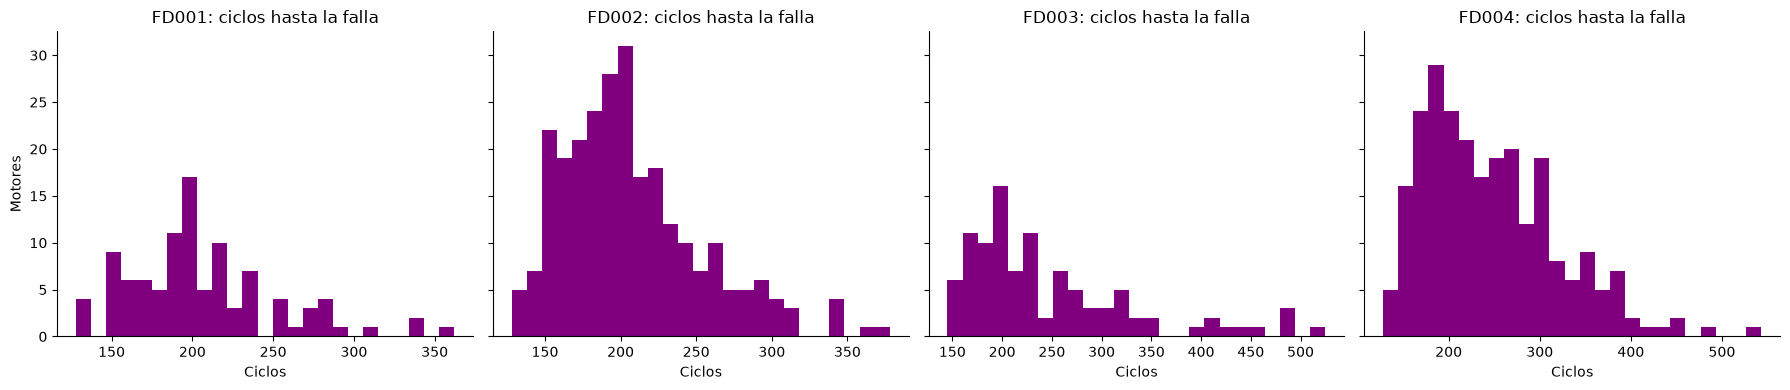

In [11]:
vida = train.groupby(["subset", "engine_id"])["cycle"].max().reset_index(name="ciclos_falla")
print(vida.groupby("subset")["ciclos_falla"].describe().round(1))

fig, ejes = plt.subplots(1, 4, figsize=(18, 4), sharey=True)
for ax, fd in zip(ejes, subsets):
    ax.hist(vida.loc[vida["subset"] == fd, "ciclos_falla"], bins=25, color="purple")
    ax.set_title(f"{fd}: ciclos hasta la falla")
    ax.set_xlabel("Ciclos")
ejes[0].set_ylabel("Motores")
plt.tight_layout()
plt.show()


- FD001 y FD002 tienen vidas parecidas (media ≈ 206 ciclos, mínimo 128).
- FD003 y FD004, con dos modos de falla, viven más y con más dispersión (media ≈ 247, máximo de 525 y 543 ciclos).

### 4.2 Test: series truncadas antes de la falla

En test, cada motor se observa solo hasta algún punto antes de fallar. Se comparan los ciclos observados en test con la vida completa en train y se revisa el RUL real al último ciclo.

ciclos_observados             RUL_final            
                     min median  max       min median  max
subset                                                    
FD001                 31  133.5  303         7   86.0  145
FD002                 21  132.0  367         6   80.0  194
FD003                 38  148.0  475         6   77.5  145
FD004                 19  153.5  486         6   88.0  195

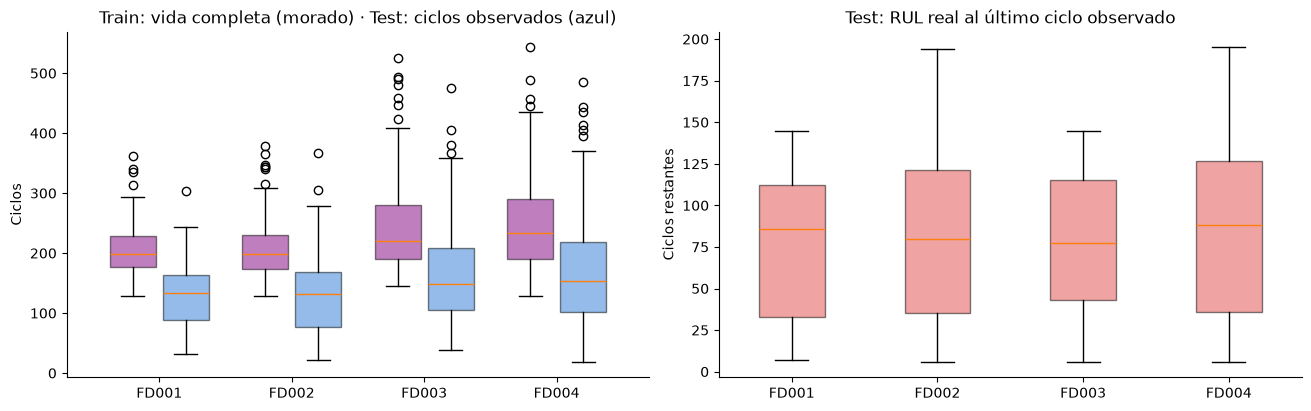

In [12]:
ultimo_test = (test.groupby(["subset", "engine"])
               .agg(ciclos_observados=("cycle", "max"), RUL_final=("RUL_final", "first"))
               .reset_index())

display(ultimo_test.groupby("subset")[["ciclos_observados", "RUL_final"]]
        .agg(["min", "median", "max"]).round(1))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4), layout="constrained")
posiciones = np.arange(len(subsets))
ax1.boxplot([vida.loc[vida["subset"] == fd, "ciclos_falla"] for fd in subsets],
            positions=posiciones - 0.2, widths=0.35, patch_artist=True,
            boxprops=dict(facecolor="purple", alpha=0.5))
ax1.boxplot([ultimo_test.loc[ultimo_test["subset"] == fd, "ciclos_observados"] for fd in subsets],
            positions=posiciones + 0.2, widths=0.35, patch_artist=True,
            boxprops=dict(facecolor=AZUL, alpha=0.5))
ax1.set(xticks=posiciones, xticklabels=subsets, ylabel="Ciclos",
        title="Train: vida completa (morado) · Test: ciclos observados (azul)")
ax2.boxplot([ultimo_test.loc[ultimo_test["subset"] == fd, "RUL_final"] for fd in subsets],
            tick_labels=subsets, patch_artist=True, boxprops=dict(facecolor=ROJO, alpha=0.5))
ax2.set(ylabel="Ciclos restantes", title="Test: RUL real al último ciclo observado")
plt.show()


- Los motores de test se observan menos ciclos que los de train (mediana de 132–154 contra 199–234), y algunos muy pocos (mínimo de 19–38 ciclos).
- El RUL real al último ciclo va de 6 a 145 en FD001/FD003 y hasta 194–195 en FD002/FD004.
- **Implicación para el modelo:** se evalúa con **una predicción por motor**, en su último ciclo observado, comparada con `RUL_final`. Además, el modelo debe funcionar con historiales cortos.

### 4.3 RUL lineal contra RUL recortado

El RUL de train baja en línea recta desde el primer ciclo. Pero al inicio de su vida el motor todavía no muestra degradación, así que sus sensores no pueden distinguir si le quedan 300 o 150 ciclos. Por eso es común **recortar** el RUL a un máximo (lineal por tramos): mientras el motor está sano, el objetivo es constante. Se comparan los recortes a 125 y 130 ciclos.


,RUL > 125 (%),RUL > 130 (%)
subset,,
FD001,38.9,36.5
FD002,39.1,36.7
FD003,49.0,47.0
FD004,48.8,46.7
Todos,44.3,42.1


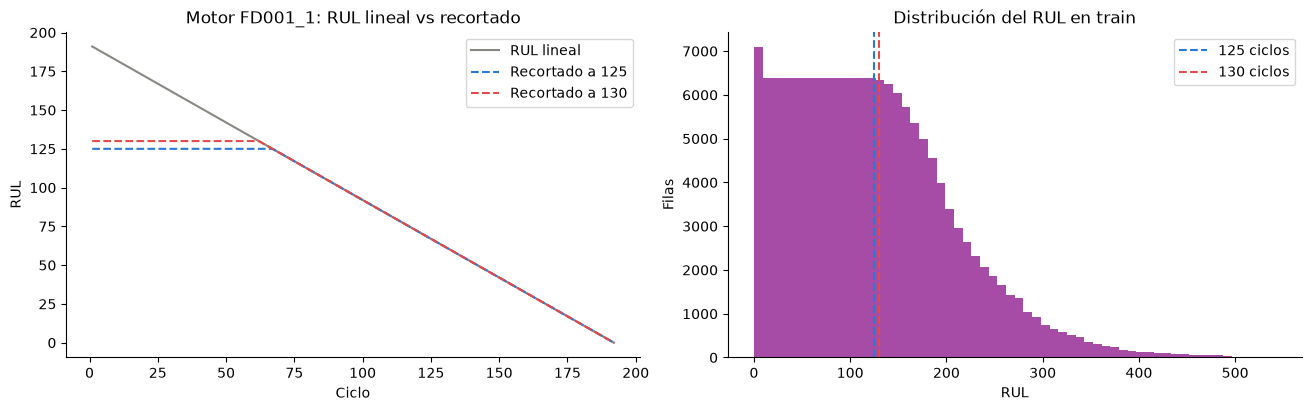

In [13]:
recorte = pd.DataFrame({
    f"RUL > {c} (%)": train.groupby("subset")["RUL"].apply(lambda r: 100 * (r > c).mean())
    for c in RUL_MAX
})
recorte.loc["Todos"] = [100 * (train["RUL"] > c).mean() for c in RUL_MAX]
display(recorte.round(1))

motor = train[train["engine_id"] == "FD001_1"]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4), layout="constrained")
ax1.plot(motor["cycle"], motor["RUL"], color=GRIS, label="RUL lineal")
for c, color in zip(RUL_MAX, (AZUL, ROJO)):
    ax1.plot(motor["cycle"], motor["RUL"].clip(upper=c), color=color, ls="--", label=f"Recortado a {c}")
ax1.set(xlabel="Ciclo", ylabel="RUL", title="Motor FD001_1: RUL lineal vs recortado")
ax1.legend()
ax2.hist(train["RUL"], bins=60, color="purple", alpha=0.7)
for c, color in zip(RUL_MAX, (AZUL, ROJO)):
    ax2.axvline(c, color=color, ls="--", label=f"{c} ciclos")
ax2.set(xlabel="RUL", ylabel="Filas", title="Distribución del RUL en train")
ax2.legend()
plt.show()


- El **44.3 %** de las filas de train tiene RUL > 125 y el **42.1 %** RUL > 130. Es más en FD003/FD004 (≈ 49 % y 47 %), porque sus motores viven más.
- Con el recorte, todas esas filas pasan a tener el mismo objetivo (125 o 130). La diferencia entre ambos valores es pequeña.


---

## 5. Condiciones de operación

Ahora obtendremos las condiciones de operación para cada subconjunto. Cada condición corresponde a **altitud**, **Mach** y **acelerador (TRA)**.

### 5.1 Filas por condición en train y test


In [14]:
pd.concat({"train": pd.crosstab(train["condicion"], train["subset"]),
           "test": pd.crosstab(test["condicion"], test["subset"])}, axis=1)


train                        test                    
subset       FD001  FD002  FD003  FD004  FD001 FD002  FD003  FD004
condicion                                                         
0_0.0_100    20631   8044  24720   9238  13096  5148  16596   6054
10_0.25_100      0   8096      0   9224      0  5107      0   6185
20_0.7_100       0   8122      0   9091      0  5063      0   6254
25_0.62_60       0   8002      0   9139      0  5042      0   6107
35_0.84_100      0   8037      0   9162      0  5148      0   6232
42_0.84_100      0  13458      0  15395      0  8483      0  10382

- **FD001 y FD003** operan solo a nivel del mar (`0_0.0_100`).
- **FD002 y FD004** reparten sus ciclos entre las **6 condiciones**: cinco con ≈ 15 % de las filas cada una y `42_0.84_100` con ≈ 25 %.
- Test tiene las mismas condiciones y proporciones que train.

### 5.2 Las seis condiciones en el espacio de operación


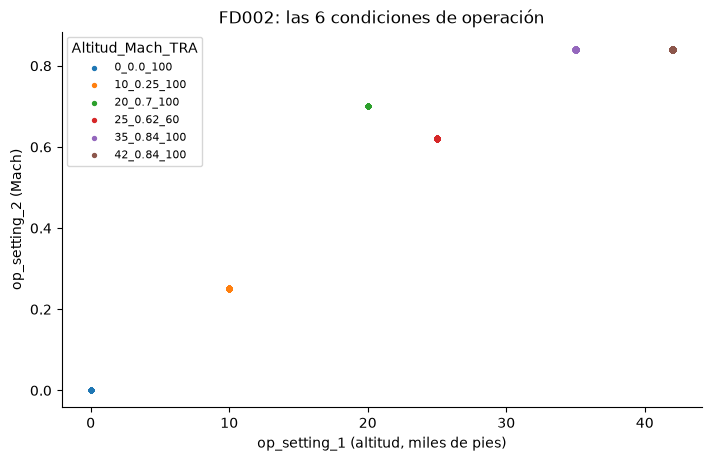

In [15]:
muestra = train[train["subset"] == "FD002"].sample(3000, random_state=42)
fig, ax = plt.subplots(figsize=(7, 4.5), layout="constrained")
for k, (cond, grupo) in enumerate(muestra.groupby("condicion")):
    ax.scatter(grupo["op_setting_1"], grupo["op_setting_2"], s=8, color=f"C{k}", label=cond)
ax.set(xlabel="op_setting_1 (altitud, miles de pies)", ylabel="op_setting_2 (Mach)",
       title="FD002: las 6 condiciones de operación")
ax.legend(title="Altitud_Mach_TRA", fontsize=8)
plt.show()


Las condiciones forman 6 grupos bien separados y sin puntos intermedios: el motor siempre opera en uno de 6 regímenes fijos. Como cada régimen cambia mucho las lecturas de los sensores, en FD002 y FD004 la condición explica más variación que el desgaste (sección 6.3).


---

## 6. Sensores

### 6.1 Sensores constantes

Vamos a calcular la desviación de cada sensor dentro de cada subconjunto. Los que dan casi 0 no aportan información para predecir y se pueden descartar del modelo de ese subconjunto.


In [16]:
std_sensores = train.groupby("subset")[Sensores].std().T.round(4)
constantes = {fd: std_sensores.index[std_sensores[fd] < 1e-3].tolist() for fd in subsets}
print("Constantes en el subconjunto completo:", constantes)
std_sensores


Constantes en el subconjunto completo: {'FD001': ['T2', 'P2', 'epr', 'farB', 'Nf_dmd', 'PCNfR_dmd'], 'FD002': [], 'FD003': ['T2', 'P2', 'farB', 'Nf_dmd', 'PCNfR_dmd'], 'FD004': []}


subset,FD001,FD002,FD003,FD004
T2,0.0000,26.3897,0.0000,26.4368
T24,0.5001,37.2894,0.5230,37.3426
T30,6.1311,105.9463,6.8104,106.1676
T50,9.0006,119.1234,9.7732,119.3276
P2,0.0000,3.6138,0.0000,3.6229
P15,0.0014,5.4318,0.0181,5.4440
P30,0.8851,146.0053,3.4373,146.8802
Nf,0.0710,145.2098,0.1583,145.3482
Nc,22.0829,335.8120,19.9803,336.9275
epr,0.0000,0.1275,0.0035,0.1277


En FD002 y FD004 ningún sensor parece constante, pero eso se debe a que la desviación mezcla las 6 condiciones. Se repite el cálculo **dentro de cada condición** (promedio de las desviaciones por condición).


In [17]:
std_condicion = train.groupby(["subset", "condicion"])[Sensores].std().groupby("subset").mean().T.round(4)
constantes_condicion = {fd: std_condicion.index[std_condicion[fd] < 1e-3].tolist() for fd in subsets}
print("Constantes dentro de cada condición:", constantes_condicion)

sin_informacion = sorted(set().union(*constantes_condicion.values()) - {"epr"})
Sensores_utiles = [s for s in Sensores if s not in sin_informacion]
print(f"Se descartan {len(sin_informacion)}: {sin_informacion}")
print(f"Quedan {len(Sensores_utiles)}: {Sensores_utiles}")
std_condicion


Constantes dentro de cada condición: {'FD001': ['T2', 'P2', 'epr', 'farB', 'Nf_dmd', 'PCNfR_dmd'], 'FD002': ['T2', 'P2', 'farB', 'Nf_dmd', 'PCNfR_dmd'], 'FD003': ['T2', 'P2', 'farB', 'Nf_dmd', 'PCNfR_dmd'], 'FD004': ['T2', 'P2', 'farB', 'Nf_dmd', 'PCNfR_dmd']}
Se descartan 5: ['Nf_dmd', 'P2', 'PCNfR_dmd', 'T2', 'farB']
Quedan 16: ['T24', 'T30', 'T50', 'P15', 'P30', 'Nf', 'Nc', 'epr', 'Ps30', 'phi', 'NRf', 'NRc', 'BPR', 'htBleed', 'W31', 'W32']


subset,FD001,FD002,FD003,FD004
T2,0.0000,0.0000,0.0000,0.0000
T24,0.5001,0.4440,0.5230,0.4793
T30,6.1311,5.6876,6.8104,6.4569
T50,9.0006,7.8393,9.7732,8.8608
P2,0.0000,0.0000,0.0000,0.0000
P15,0.0014,0.0036,0.0181,0.0148
P30,0.8851,0.5848,3.4373,1.9025
Nf,0.0710,0.1888,0.1583,0.2067
Nc,22.0829,17.2962,19.9803,17.6007
epr,0.0000,0.0015,0.0035,0.0047


- Dentro de cada condición, **`T2`, `P2`, `farB`, `Nf_dmd` y `PCNfR_dmd` son constantes en los cuatro subconjuntos**: solo dependen de la condición de operación, no del desgaste. Se descartan.
- `epr` es constante solo en FD001; en los otros tres sí varía, así que se conserva en la lista general y se descarta solo al modelar FD001.
- Quedan **16 sensores útiles**: `T24`, `T30`, `T50`, `P15`, `P30`, `Nf`, `Nc`, `epr`, `Ps30`, `phi`, `NRf`, `NRc`, `BPR`, `htBleed`, `W31`, `W32`.

### 6.2 Trayectorias de degradación

Se grafican cuatro sensores de cinco motores de FD001 contra los ciclos que les faltan para fallar. Se usa una media móvil de 10 ciclos para ver la tendencia a través del ruido.


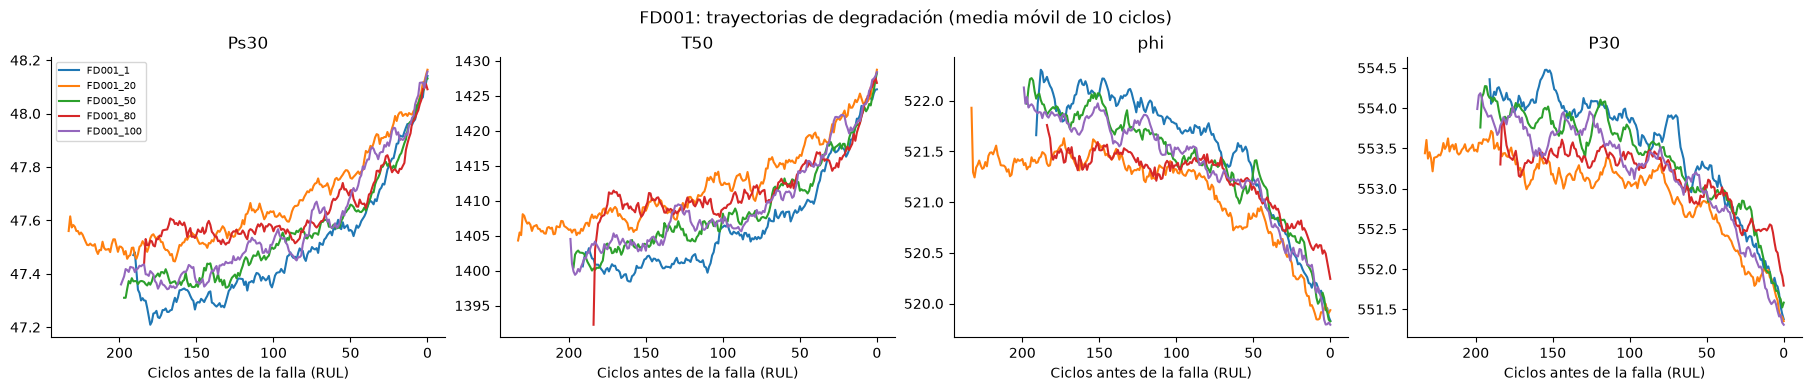

In [18]:
claves = ["Ps30", "T50", "phi", "P30"]
motores = ["FD001_1", "FD001_20", "FD001_50", "FD001_80", "FD001_100"]

fig, ejes = plt.subplots(1, 4, figsize=(18, 3.8), layout="constrained")
for ax, sensor in zip(ejes, claves):
    for k, motor_id in enumerate(motores):
        m = train[train["engine_id"] == motor_id]
        ax.plot(m["RUL"], m[sensor].rolling(10, min_periods=1).mean(), color=f"C{k}", label=motor_id)
    ax.invert_xaxis()
    ax.set(title=sensor, xlabel="Ciclos antes de la falla (RUL)")
ejes[0].legend(fontsize=7)
fig.suptitle("FD001: trayectorias de degradación (media móvil de 10 ciclos)")
plt.show()


- Lejos de la falla los sensores se mantienen casi planos, y la degradación se acelera en los últimos ≈ 100 ciclos. Esto respalda el **recorte del RUL**: en la parte plana no hay información para distinguir cuántos ciclos quedan.
- Cada motor parte de un nivel distinto (desgaste inicial y variación de fabricación), pero todos convergen al acercarse la falla.
- Aun con la media móvil hay ruido. Para el modelo conviene usar características suavizadas o de ventana (media móvil, pendiente reciente) además del valor del ciclo actual.

### 6.3 Efecto de normalizar por condición de operación

En FD002 y FD004 cada condición desplaza los valores de los sensores. Para quitar ese efecto se **estandariza cada sensor dentro de su condición**, con la media y la desviación calculadas **solo con train**:

$$z = \frac{x - \mu_{\text{condición}}}{\sigma_{\text{condición}}}$$


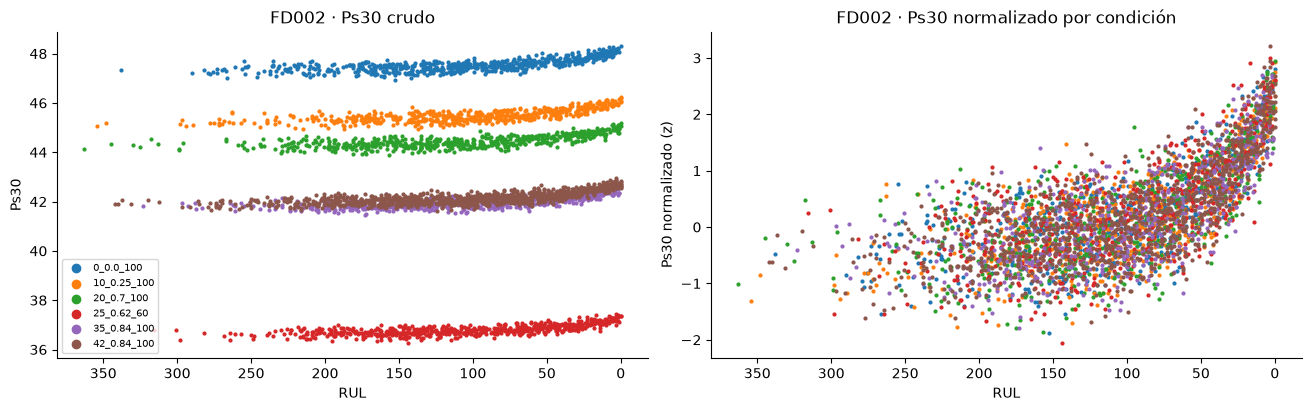

In [19]:
estadisticas_condicion = train.groupby("condicion")[Sensores_utiles].agg(["mean", "std"])

def normalizar_por_condicion(df):
    salida = df.copy()
    for s in Sensores_utiles:
        media = df["condicion"].map(estadisticas_condicion[(s, "mean")])
        desv = df["condicion"].map(estadisticas_condicion[(s, "std")])
        salida[s] = (df[s] - media) / desv
    return salida

train_norm = normalizar_por_condicion(train)

muestra = train_norm[train_norm["subset"] == "FD002"].sample(4000, random_state=42)
crudo = train.loc[muestra.index]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4), layout="constrained")
for k, cond in enumerate(sorted(muestra["condicion"].unique())):
    sel = muestra["condicion"] == cond
    ax1.scatter(crudo.loc[sel, "RUL"], crudo.loc[sel, "Ps30"], s=4, color=f"C{k}", label=cond)
    ax2.scatter(muestra.loc[sel, "RUL"], muestra.loc[sel, "Ps30"], s=4, color=f"C{k}")
ax1.set(xlabel="RUL", ylabel="Ps30", title="FD002 · Ps30 crudo")
ax2.set(xlabel="RUL", ylabel="Ps30 normalizado (z)", title="FD002 · Ps30 normalizado por condición")
for ax in (ax1, ax2):
    ax.invert_xaxis()
ax1.legend(fontsize=7, markerscale=3)
plt.show()


- **Crudo (izquierda):** `Ps30` forma 6 bandas separadas, una por condición. La diferencia entre bandas (≈ 11 unidades) es mucho mayor que el cambio por desgaste dentro de una banda (≈ 1 unidad). Por eso, sin normalizar, la correlación con el RUL en FD002 sale ≈ 0.
- **Normalizado (derecha):** las 6 condiciones se encimadan en una sola nube y aparece claramente la tendencia de degradación al acercarse la falla.
- Este paso es el que permite juntar subconjuntos con distintas condiciones (por ejemplo, para el modelo no supervisado con todo train). En test se aplica con las **mismas** medias y desviaciones de train.


### 6.4 Comportamiento de cada sensor al acercarse la falla

La desviación (6.1) dice si un sensor cambia; esta gráfica muestra **cómo** cambia. Cada panel es un sensor, normalizado por condición. Los motores se alinean por los ciclos que les faltan para fallar: a la derecha están lejos de la falla y a la izquierda a punto de fallar. La línea es la mediana de todos los motores de cada subconjunto y la banda el rango donde está el 80 % de ellos (percentiles 10 a 90). La línea punteada marca el recorte del RUL en 130 ciclos.

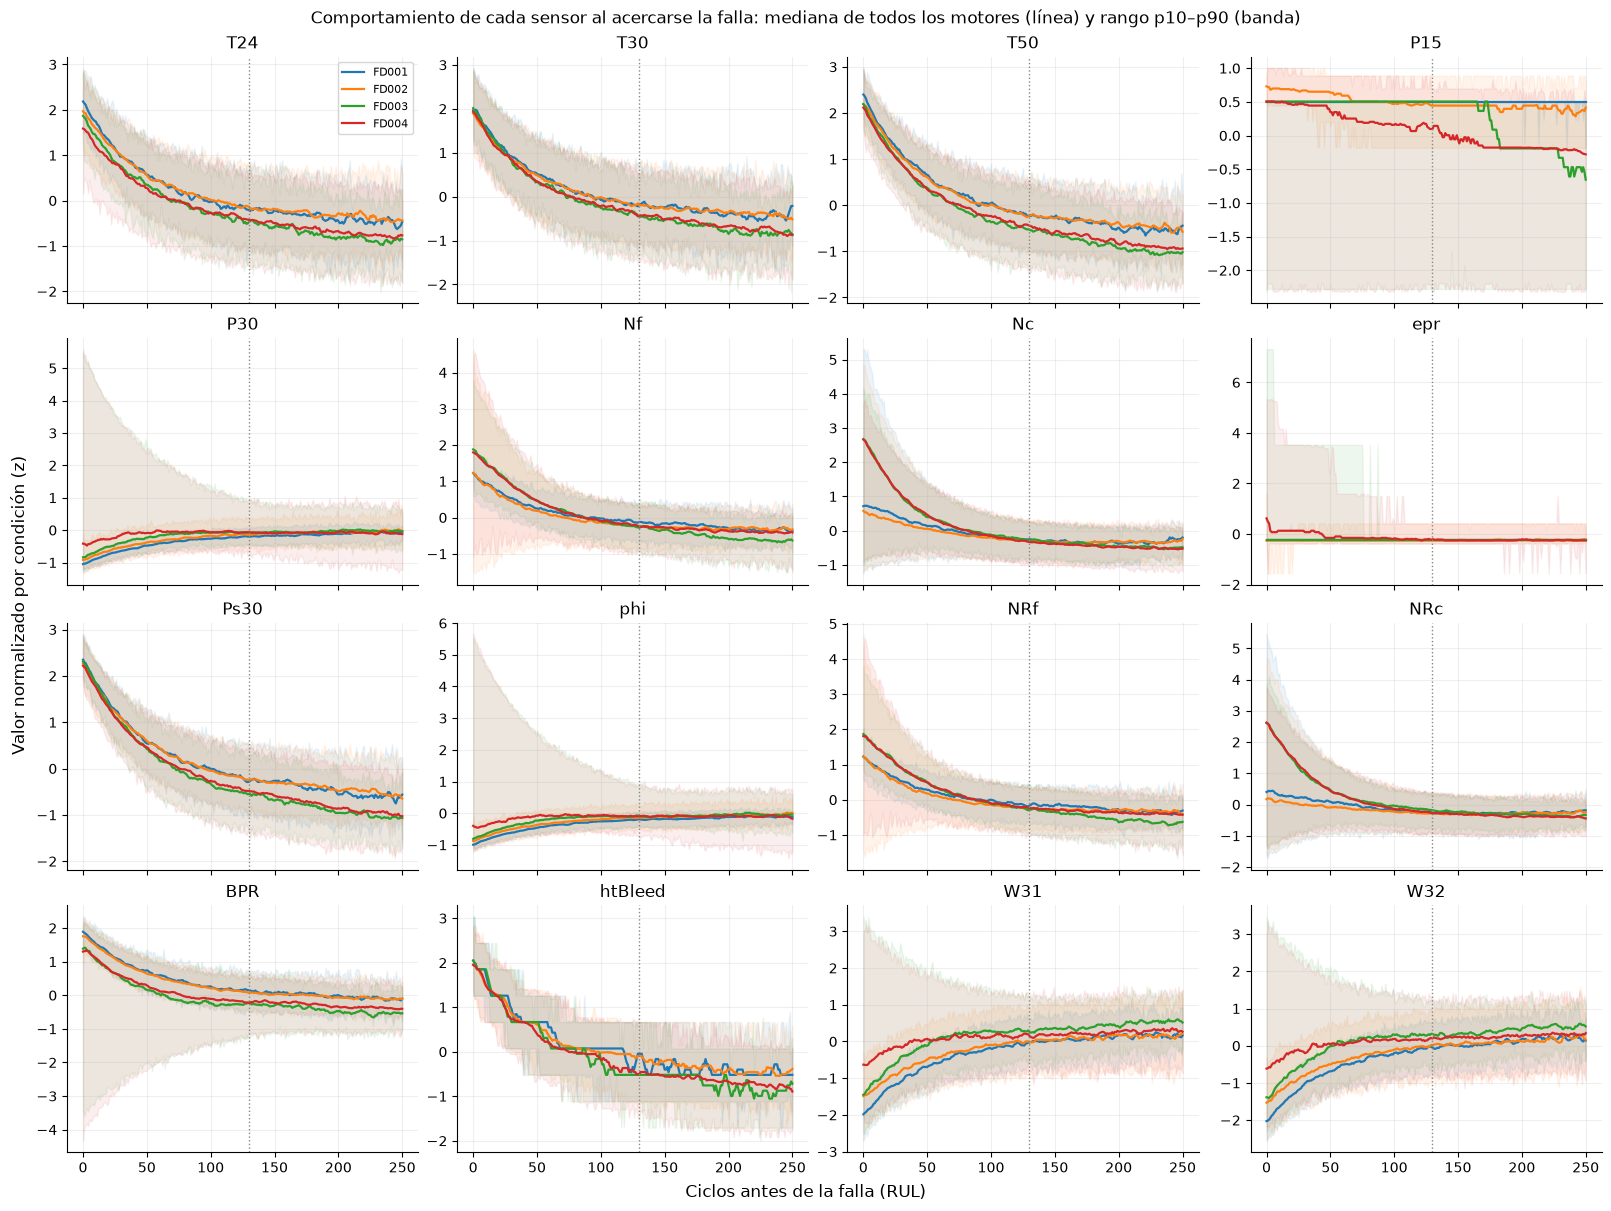

In [20]:
RUL_VISTA = 250   # se grafican los últimos 250 ciclos antes de la falla
colores_fd = dict(zip(subsets, ["C0", "C1", "C2", "C3"]))

vista = train_norm[train_norm["RUL"] <= RUL_VISTA]
resumen = vista.groupby(["subset", "RUL"])[Sensores_utiles].quantile([0.1, 0.5, 0.9]).unstack()

n_col = 4
n_fil = -(-len(Sensores_utiles) // n_col)
fig, ejes = plt.subplots(n_fil, n_col, figsize=(16, 3 * n_fil), sharex=True, layout="constrained")
for ax, sensor in zip(ejes.flat, Sensores_utiles):
    for fd in subsets:
        r = resumen.loc[fd, sensor]
        ax.plot(r.index, r[0.5].rolling(5, center=True, min_periods=1).mean(),
                color=colores_fd[fd], lw=1.6, label=fd)
        ax.fill_between(r.index, r[0.1], r[0.9], color=colores_fd[fd], alpha=0.08)
    ax.axvline(130, color=GRIS, ls=":", lw=1)   # recorte del RUL
    ax.set_title(sensor)
    ax.invert_xaxis()
    ax.grid(alpha=0.2)
for ax in list(ejes.flat)[len(Sensores_utiles):]:
    ax.axis("off")
ejes.flat[0].legend(fontsize=8)
fig.supxlabel("Ciclos antes de la falla (RUL)")
fig.supylabel("Valor normalizado por condición (z)")
fig.suptitle("Comportamiento de cada sensor al acercarse la falla: "
             "mediana de todos los motores (línea) y rango p10–p90 (banda)")
plt.show()

- **Casi todos los sensores están planos lejos de la falla y cambian rápido en los últimos ≈ 100–130 ciclos.** A la derecha de la línea punteada casi no hay señal: esto respalda el recorte del RUL (4.3, 11.3).
- **Las bandas son anchas y las medianas ruidosas:** cada motor se comporta distinto y cada lectura varía mucho. Esto respalda el uso de ventanas, que promedian y miden la tendencia (10.3).
- **En `P30`, `phi`, `BPR`, `W31` y `W32`, la banda de FD003/FD004 se abre hacia el lado contrario cerca de la falla:** una parte de los motores sube mientras la mayoría baja. Son los dos modos de falla (compresor y ventilador) moviendo el sensor en direcciones opuestas. Por eso su correlación con el RUL es ≈ 0 en esos subconjuntos (7.3), y por eso se entrena un modelo por subconjunto.
- **`Nc` y `NRc` suben mucho más en FD003/FD004**, por el efecto de la falla del ventilador sobre la velocidad del núcleo.
- **`P15` y `epr` cambian en escalones**, porque toman pocos valores distintos. `epr` es casi plano en FD001/FD002, coherente con su descarte en esos subconjuntos (10.2).

---

## 7. Correlación de cada sensor con el RUL

### 7.1 Correlación sin normalizar

Ahora se calculará la correlación de Pearson de cada sensor con el RUL en cada subconjunto. Habrá sensores cuya desviación es σ = 0. Si observamos la fórmula:

$$r = \frac{\text{cov}(\text{sensor}, \text{RUL})}{\sigma_{\text{sensor}} \cdot \sigma_{\text{RUL}}}$$

Cuando un sensor no cambia y su desviación es 0, la división no está definida y pandas devuelve NaN. Es decir, si un sensor nunca cambia, no puede moverse con el RUL.


In [21]:
corr_rul = train.groupby("subset").apply(lambda d: d[Sensores].corrwith(d["RUL"])).T.round(2)
corr_rul

subset,FD001,FD002,FD003,FD004
T2,NaN,-0.00,NaN,0.00
T24,-0.61,-0.00,-0.59,-0.00
T30,-0.58,-0.03,-0.62,-0.03
T50,-0.68,-0.04,-0.66,-0.05
P2,0.00,-0.00,0.00,0.00
P15,-0.13,-0.00,-0.22,0.00
P30,0.66,0.00,-0.32,-0.00
Nf,-0.56,0.00,-0.66,0.00
Nc,-0.39,-0.02,-0.55,-0.02
epr,NaN,0.00,-0.36,-0.01


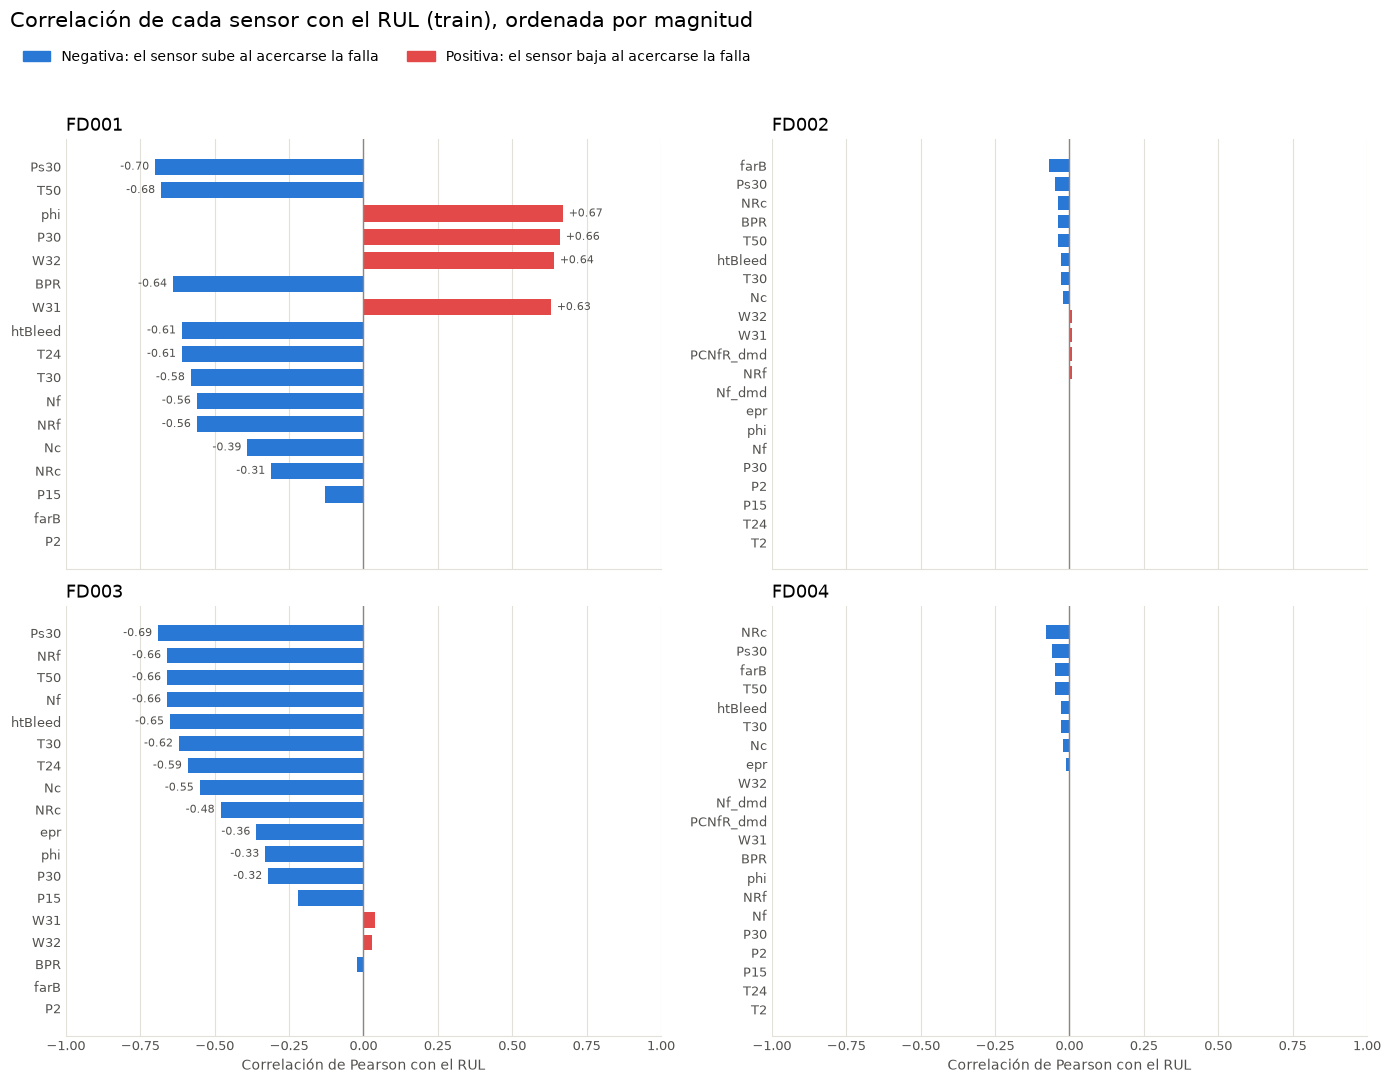

In [22]:
fig, ejes = plt.subplots(2, 2, figsize=(14, 11), sharex=True)
for ax, fd in zip(ejes.ravel(), subsets):
    orden = corr_rul[fd].dropna().sort_values(key=abs)   # barh dibuja de abajo hacia arriba: el mayor queda arriba
    colores = [AZUL if v < 0 else ROJO for v in orden] # type: ignore
    ax.barh(orden.index, orden.values, color=colores, height=0.7)
    ax.axvline(0, color=GRIS, lw=1)

    # etiqueta solo las correlaciones relevantes (|r| >= 0.3)
    for i, v in enumerate(orden.values):
        if abs(v) >= 0.3:
            ax.text(v + (0.02 if v > 0 else -0.02), i, f"{v:+.2f}", va="center",
                    ha="left" if v > 0 else "right", fontsize=8, color=TEXTO)

    ax.set_title(fd, loc="left", fontsize=13)
    ax.set_xlim(-1, 1)
    ax.grid(axis="x", color=REJILLA, lw=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors=TEXTO, labelsize=9, length=0)
    for lado in ["top", "right", "left"]:
        ax.spines[lado].set_visible(False)
    ax.spines["bottom"].set_color(REJILLA)

for ax in ejes[1]:
    ax.set_xlabel("Correlación de Pearson con el RUL", color=TEXTO)

fig.legend(handles=[Patch(color=AZUL, label="Negativa: el sensor sube al acercarse la falla"),
                    Patch(color=ROJO, label="Positiva: el sensor baja al acercarse la falla")],
           loc="upper left", bbox_to_anchor=(0.01, 0.955), ncol=2, frameon=False, fontsize=10)
fig.suptitle("Correlación de cada sensor con el RUL (train), ordenada por magnitud",
             x=0.01, ha="left", fontsize=15)
plt.tight_layout(rect=[0, 0, 1, 0.93]) # type: ignore
plt.savefig("Images/Correlacion sensores vs RUL.png", dpi=300, bbox_inches="tight")
plt.show()


En el subconjunto FD001 hay sensores fuertemente relacionados con el RUL, aunque por sí solos no alcanzarían para describirlo.

| Fuerza | Sensores (r con el RUL) | Interpretación |
|---|---|---|
| Moderada-fuerte (0.6 - 0.7) | Ps30 -0.70, T50 -0.68, phi +0.67, P30 +0.66, BPR -0.64, W32 +0.64, W31 +0.63, T24 -0.61, htBleed -0.61 | Siguen claramente la degradación. Son los mejores candidatos para el modelo. |
| Moderada (0.5 - 0.6) | T30 -0.58, Nf -0.56, NRf -0.56 | También fuertes. |
| Débil (0.3 - 0.4) | Nc -0.39, NRc -0.31 | Aportan poco por sí solos. |
| Casi nula (<0.15) | P15 -0.13, P2 0.00, farB 0.00 | No siguen la degradación. |
| Sin valor | T2, epr, Nf_dmd, PCNfR_dmd | Constantes en FD001; se descartan. |

Para P2 y farB salen ≈ 0 en vez de NaN porque varían en los decimales; esto no cambia la decisión de no incluirlos en el análisis.

Qué pasa con el motor al acercarse a la falla:

- Con las lecturas **negativas** el sensor sube: las temperaturas (`T24`, `T30`, `T50`), la presión estática `Ps30`, el sangrado `htBleed`, la relación de bypass `BPR` y las velocidades del ventilador (`Nf`, `NRf`). El motor trabaja más caliente y con más esfuerzo para entregar el mismo empuje.
- Con las lecturas **positivas** el sensor baja: `P30`, `phi`, `W31`, `W32`. Todos dependen del flujo que entrega el HPC, que es el componente que se degrada en FD001.

*El compresor de alta pierde eficiencia y el resto del motor compensa calentándose y esforzándose más.*

En **FD002 y FD004** todas las correlaciones salen ≈ 0. No es que los sensores no sigan la degradación: el efecto de las 6 condiciones de operación tapa la señal (sección 6.3). En la sección 7.3 se repite el cálculo con los sensores normalizados.

### 7.2 Correlación motor por motor (FD001)


In [23]:
fd001 = train[train["subset"] == "FD001"]

corr_por_motor = fd001.groupby("engine").apply(lambda d: d[Sensores].corrwith(d["RUL"]))

resumen = pd.DataFrame({
    "global": fd001[Sensores].corrwith(fd001["RUL"]),
    "media_motor": corr_por_motor.mean(),
    "min": corr_por_motor.min(),
    "max": corr_por_motor.max(),
}).dropna().sort_values("media_motor", key=abs, ascending=False).round(2)
resumen


,global,media_motor,min,max
Ps30,-0.70,-0.81,-0.87,-0.68
phi,0.67,0.79,0.64,0.86
T50,-0.68,-0.78,-0.84,-0.64
P30,0.66,0.76,0.59,0.86
BPR,-0.64,-0.72,-0.81,-0.62
W32,0.64,0.72,0.58,0.80
W31,0.63,0.71,0.60,0.82
NRf,-0.56,-0.69,-0.86,-0.13
Nf,-0.56,-0.68,-0.86,-0.15
T24,-0.61,-0.68,-0.79,-0.50


Las correlaciones anteriores se calcularon con todos los motores del subconjunto juntos. Calculadas motor por motor son más fuertes (≈ 0.8 para `Ps30`, `T50`, `phi` y `P30`), lo que indica que parte de la variación se debe a diferencias entre motores (desgaste inicial distinto) y no al sensor.

`Nc` y `NRc` son la excepción: su correlación cambia de signo entre motores (de −0.86 a +0.77/+0.84), así que no siguen un patrón común de degradación.

### 7.3 Correlación con sensores normalizados y RUL recortado

Se repite la correlación con los 16 sensores útiles en cuatro versiones: cruda, normalizada por condición y normalizada con el RUL recortado a 125 y a 130. Para comparar, se resume con el promedio de |r| de cada subconjunto.


In [24]:
def correlacion(df, rul):
    return df.groupby("subset").apply(lambda d: d[Sensores_utiles].corrwith(rul.loc[d.index])).T

versiones = {
    "Cruda": correlacion(train, train["RUL"]),
    "Normalizada": correlacion(train_norm, train_norm["RUL"]),
}
for c in RUL_MAX:
    versiones[f"Normalizada + RUL ≤ {c}"] = correlacion(train_norm, train_norm["RUL"].clip(upper=c))

media_abs = pd.DataFrame({nombre: corr.abs().mean() for nombre, corr in versiones.items()}).round(3)
print("Promedio de |r| sobre los sensores útiles")
display(media_abs)


Promedio de |r| sobre los sensores útiles


,Cruda,Normalizada,Normalizada + RUL ≤ 125,Normalizada + RUL ≤ 130
subset,,,,
FD001,0.557,0.557,0.623,0.621
FD002,0.017,0.447,0.502,0.500
FD003,0.429,0.429,0.473,0.473
FD004,0.019,0.389,0.435,0.435


| Subconjunto | Cruda | Normalizada | + RUL ≤ 125 | + RUL ≤ 130 |
|:--|:--:|:--:|:--:|:--:|
| FD001 | 0.557 | 0.557 | **0.623** | 0.621 |
| FD002 | 0.017 | **0.447** | **0.502** | 0.500 |
| FD003 | 0.429 | 0.429 | **0.473** | 0.473 |
| FD004 | 0.019 | **0.389** | **0.435** | 0.435 |

- **Normalizar por condición** recupera la señal en FD002 (0.017 → 0.447) y FD004 (0.019 → 0.389). En FD001 y FD003 no cambia nada, porque tienen una sola condición.
- **Recortar el RUL** sube la correlación en los cuatro subconjuntos (≈ +0.04 a +0.07), porque elimina la parte plana donde los sensores no cambian.
- **125 contra 130:** la diferencia es mínima (≤ 0.002). La elección se hará al preparar los datos, comparando el error de los modelos en validación.


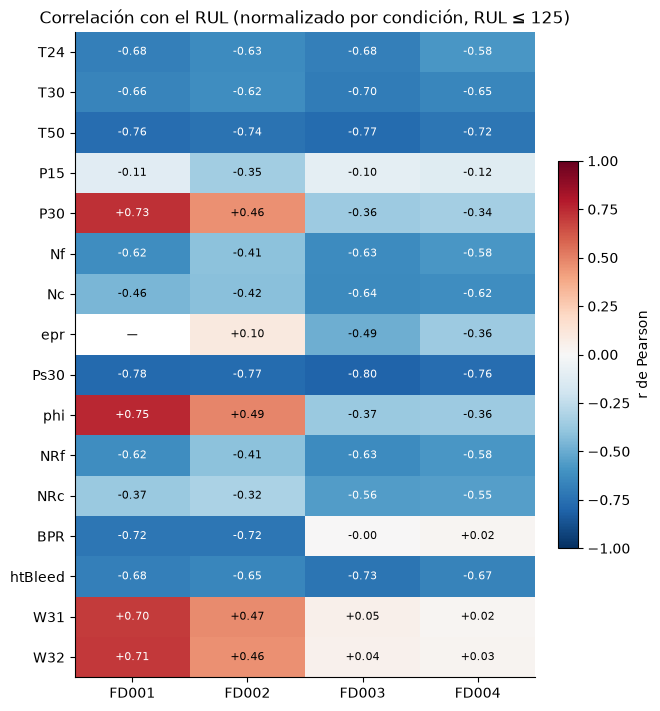

In [25]:
corr_final = versiones["Normalizada + RUL ≤ 125"].round(2)

fig, ax = plt.subplots(figsize=(6.5, 7), layout="constrained")
im = ax.imshow(corr_final.values, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
ax.set(xticks=range(len(subsets)), xticklabels=subsets,
       yticks=range(len(corr_final)), yticklabels=corr_final.index,
       title="Correlación con el RUL (normalizado por condición, RUL ≤ 125)")
for i in range(corr_final.shape[0]):
    for j in range(corr_final.shape[1]):
        v = corr_final.iat[i, j]
        texto = "—" if pd.isna(v) else f"{v:+.2f}"
        ax.text(j, i, texto, ha="center", va="center", fontsize=8,
                color="white" if abs(v) > 0.5 else "black")
fig.colorbar(im, ax=ax, shrink=0.6, label="r de Pearson")
plt.show()


- **Sensores comunes a todos los subconjuntos:** `Ps30` (≈ −0.78), `T50` (≈ −0.75), `T30`, `T24` y `htBleed` (≈ −0.6 a −0.7) siguen la degradación igual en los cuatro.
- **Efecto del segundo modo de falla (ventilador) en FD003 y FD004:**
  - `BPR`, `W31` y `W32` pierden la correlación (≈ 0), aunque en FD001/FD002 son de los más fuertes (≈ 0.7).
  - `P30` y `phi` cambian de signo: de +0.73/+0.75 en FD001 a ≈ −0.36 en FD003.

  Cuando la falla es del ventilador, estos sensores se mueven en otra dirección que cuando es del HPC, y al mezclar motores con ambos modos la correlación se cancela.
- **`epr`** no tiene valor en FD001 (constante) y es débil en FD002.


---

## 8. Conclusiones del EDA y decisiones para el preprocesamiento

1. **Calidad:** no hay nulos ni duplicados. Hay 709 motores en train y 707 en test, y cada motor de test tiene su RUL real.
2. **Condiciones de operación:** en FD002 y FD004 las 6 condiciones dominan la variación de los sensores (correlación cruda ≈ 0.02). Se **normalizará cada sensor por condición** (z-score) con medias y desviaciones calculadas **solo con train**, y se aplicarán igual a test, que usa las mismas 6 condiciones.
3. **Sensores:**
   - se descartan `T2`, `P2`, `farB`, `Nf_dmd` y `PCNfR_dmd`, constantes dentro de cada condición en los cuatro subconjuntos;
   - `epr` se descarta solo en FD001;
   - quedan 16 sensores (15 en FD001).
4. **Modos de falla:** en FD003/FD004 los sensores relevantes cambian (`BPR`, `W31` y `W32` ≈ 0; `P30` y `phi` cambian de signo). Por eso conviene **un modelo por subconjunto**, y un modelo no lineal puede aprovechar mejor la mezcla de dos modos de falla.
5. **Objetivo:** el RUL se **recortará** porque el motor no muestra degradación al inicio (44 % de las filas tienen RUL > 125 y 42 % RUL > 130). El recorte sube la correlación en todos los subconjuntos. La diferencia entre 125 y 130 es mínima, así que se eligió con validación: **130** (sección 11.3).
6. **Ruido y diferencias entre motores:** las trayectorias son ruidosas y cada motor parte de un nivel distinto (correlación motor por motor ≈ 0.8 contra ≈ 0.7 global). Se agregarán características de ventana: media móvil y pendiente reciente de cada sensor.
7. **Evaluación:** test está truncado. Se predice una vez por motor, en su **último ciclo observado**, y se compara con `RUL_final`. Para elegir hiperparámetros, la validación se separará **por motor** (`engine_id`), no por filas, para no repartir ciclos de un mismo motor entre entrenamiento y validación.


---

## 9. Trabajo previo

Antes de modelar se revisaron trabajos públicos que predicen el RUL en C-MAPSS: 7 notebooks de Kaggle [[2]](#ref2), [[4]](#ref4), [[5]](#ref5), [[12]](#ref12)–[[15]](#ref15), el repositorio *rul_codes_open* [[3]](#ref3) y 6 repositorios de GitHub [[6]](#ref6)–[[11]](#ref11). El objetivo es (1) definir un **baseline** comparable y (2) aprovechar lo que ya se sabe para tomar decisiones de preprocesamiento y modelado.

### 9.1 Criterio de comparación

Los trabajos miden el RMSE de formas distintas, y eso cambia mucho los números (de ≈ 11 a ≈ 46 en FD001 con modelos parecidos). Solo se consideran comparables los que siguen el **protocolo oficial** [[1]](#ref1):

- RUL de entrenamiento recortado a 125 ciclos;
- **una predicción por motor de test**, en su último ciclo observado;
- comparada con el RUL real de `RUL_FD00X` **sin recortar**.

Se excluyen los que evalúan sobre todas las filas de test, sobre una validación sacada de train o solo con R².

### 9.2 Fuentes revisadas

| Fuente | Subconj. | Ventanas | Norm. por condición | Modelos | Protocolo | RMSE test (FD001 / FD002 / FD003 / FD004) |
|:--|:--|:--|:--|:--|:--|:--|
| Kaggle · *predictive-maintenance-nasa-turbofan-regression* [[2]](#ref2) | FD001 | No (1 ciclo) | — | KNN, SVR, RF, LSTM |  Oficial | RF **17.96**; LSTM (1 paso) 19.74 |
| *rul_codes_open* [[3]](#ref3) | 4 | No (1 ciclo) | No | RF, XGBoost, SVR |  Oficial | RF **17.76 / 29.16 / 20.59 / 30.15**; XGBoost 18.44 / 29.35 / 21.29 / **29.89** |
| *rul_codes_open*, DL [[3]](#ref3) | 4 | 30 ciclos | No | LSTM, 1D-CNN |  Oficial | LSTM 15.13 / 27.70 / 14.03 / 28.37 |
| Kaggle · *rul-prediction-using-lstm-for-aircraft-engine* [[4]](#ref4) | FD001 | 30 ciclos | — | LSTM |  Oficial | LSTM **15.30** |
| Kaggle · *fleet-readiness-engine-rul-on-nasa-c-mapss* [[5]](#ref5) | 4 | 30 ciclos | Sí | Ridge, LightGBM, 1D-CNN, Chronos-2 |  RUL real **recortado** | LightGBM 11.46 / 11.03 / 9.96 / 11.59 |
| GitHub · PiyushBhamare2111 [[6]](#ref6) | 4 | 30 ciclos | Sí | Gradient boosting |  Oficial | 13.27 / 25.80 / 15.02 / 26.26 |
| GitHub · yz-shift [[7]](#ref7) | 4 | Sí | Sí | LightGBM, RF |  Oficial | 13.92 / 25.82 / 14.33 / 26.75 |
| GitHub · vatsav4 [[8]](#ref8) | FD001 | 30 ciclos | — | XGBoost, RF |  Oficial | 12.82 |
| GitHub · Dyaus2 [[9]](#ref9) | FD001, FD003 | Sí | Sí | Gradient boosting |  Oficial | 16.26 / — / 15.16 / — |
| GitHub · KayDee6070 [[10]](#ref10) | FD001 | Sí | — | XGBoost, RF |  Último ciclo | 17.56 |
| GitHub · dossebamba [[11]](#ref11) | FD001 | Sí | — | RF, XGBoost |  Oficial | 18.92 |
| Kaggle · *nasa-turbofan-jet-engine* [[12]](#ref12) | FD001 | Intentadas (no se crearon) | — | LR, KNN, RF, GB, XGB, LGBM |  Todas las filas, sin recorte | ≈ 46 |
| Kaggle · *predicting-failures* [[13]](#ref13) | FD001 | Medias móviles de 2–5 | — | LR, Ridge, RF, LGBM |  Validación de train | ≈ 41–45 |
| Kaggle · *predicting-remaining-useful-life-turbofan-engine* [[14]](#ref14) | FD001 | No | — | LightGBM |  Solo R² | — |
| Kaggle · *predicting-turbofan-engine-rul* [[15]](#ref15) | FD001 | — | — | Solo EDA |  | — |

Como referencia de deep learning publicada: la CNN de Babu et al. [[16]](#ref16) reporta 18.45 / 30.29 / 19.82 / 29.16.


### 9.3 Lecciones de los trabajos previos y decisiones de este proyecto

| Lección | Evidencia en otros trabajos | Decisión en este proyecto |
|:--|:--|:--|
| **Recortar el RUL de entrenamiento** (RUL lineal por tramos [[17]](#ref17)) mejora mucho el error: al inicio el motor no muestra degradación. | −10.9 ciclos en validación [[7]](#ref7). XGBoost lineal contra recortado: 33.08 → 29.89 en FD004 [[3]](#ref3). | RUL recortado a **130**: se eligió con validación entre sin recorte, 125 y 130 (sección 11.3). |
| **Normalizar por condición de operación** es la mejora más grande en FD002/FD004, más que cambiar de modelo. | 18.35 → 10.32 (FD002) y 19.27 → 11.32 (FD004) [[5]](#ref5). Sin normalizar: ≈ 29–30 en ambos [[3]](#ref3). | z-score de cada sensor **por condición**, ajustado solo con train. |
| **Las ventanas deslizantes** superan a la lectura de un solo ciclo. | −6.7 ciclos al pasar de un ciclo a ventana [[7]](#ref7). En FD001, un ciclo ≈ 18 [[2]](#ref2), [[3]](#ref3) contra ventanas ≈ 13 [[6]](#ref6)–[[8]](#ref8). | Ventanas de **70 ciclos** con estadísticas por sensor (último valor, media, desviación, mínimo, máximo, pendiente). La literatura usa 30; la longitud se eligió con validación (sección 10.10). |
| **Los modelos de árboles** le ganan a los lineales: la degradación no es lineal. | Ridge 16.32 contra LightGBM 11.01 [[5]](#ref5). Regresión lineal 18.58 contra LightGBM 14.57 en FD001 [[7]](#ref7). | Regresión lineal solo como base; modelos principales: **Random Forest y gradient boosting**. |
| **Un modelo por subconjunto**: los dos modos de falla mueven los sensores en direcciones opuestas. | Entrenamiento por subconjunto en [[5]](#ref5) y en la mayoría de los trabajos revisados. | Un modelo por FD00X (también se confirma en el EDA, sección de correlaciones). |
| **Validar separando por motor**, no por filas. | Grupos por motor en [[5]](#ref5), [[7]](#ref7), [[9]](#ref9). Mezclar ventanas del mismo motor da una validación optimista [[8]](#ref8). | Validación cruzada con `GroupKFold` por `engine_id`. |
| **Algunos motores de test tienen historiales cortos** (menos de 30 ciclos en FD002/FD004). | Ventanas con los ciclos disponibles o con relleno [[5]](#ref5). | Ventanas con `min_periods=1`, igual en train y test. |
| **Una LSTM solo sirve si ve la secuencia.** Con un solo paso de tiempo es peor que un Random Forest. | LSTM de 1 paso 19.74 contra RF 17.96 [[2]](#ref2). Con ventanas de 30: LSTM 15.30 [[4]](#ref4). | En la fase de deep learning se usan las **mismas ventanas** como secuencias de 30 × sensores. |
| **Con pocos motores, deep learning entrenado desde cero no siempre le gana a los árboles.** | 1D-CNN 15.12 contra LightGBM 11.01 [[5]](#ref5). | DL se compara contra el mejor modelo tradicional, no se asume que gane. |
| **Hay que verificar que las características realmente se creen.** | Un filtro de nombres dejó la lista de sensores vacía y las ventanas nunca se calcularon [[12]](#ref12). | Revisar la forma y las columnas después de cada paso de preprocesamiento. |
| **Reportar el protocolo de evaluación** y ambas versiones del RMSE. | Contra el RUL recortado, FD002/FD004 bajan de ≈ 23–26 a ≈ 11–13 con el mismo modelo [[5]](#ref5), [[7]](#ref7). | Se reporta el RMSE contra el RUL completo (principal) **y** contra el recortado, más la *score NASA* [[1]](#ref1). |

### 9.4 Baseline a superar (ML tradicional)

Se toma el mejor modelo tradicional de cada fuente comparable y se promedia por subconjunto:

| Nivel | Fuentes | FD001 | FD002 | FD003 | FD004 |
|:--|:--|:--:|:--:|:--:|:--:|
| **1. Kaggle, sin ventanas** | [[2]](#ref2), [[3]](#ref3) | 17.86 | 29.16 | 20.59 | 29.89 |
| **2. Todas las fuentes comparables** | [[2]](#ref2), [[3]](#ref3), [[6]](#ref6)–[[11]](#ref11) | 16.06 | 26.93 | 16.28 | 27.63 |
| Referencia con RUL real recortado | [[5]](#ref5) (LightGBM) | 11.46 | 11.03 | 9.96 | 11.59 |

FD002 y FD004 tienen pocas fuentes comparables (2–3), así que su baseline es menos robusto.


---

## 10. Preparación de datos para ML

Se aplican las decisiones de la sección 8 (y de los trabajos previos, sección 9.3), **por subconjunto**:

1. Sensores útiles del subconjunto.
2. Normalización por condición de operación, ajustada solo con train.
3. RUL de entrenamiento recortado a 130 (elegido con validación, sección 11.3).
4. Ventanas deslizantes de 70 ciclos (elegidas con validación, sección 10.10) resumidas en estadísticas por sensor.
5. En test, solo la última ventana de cada motor.

### 10.1 Parámetros


In [26]:
from sklearn.model_selection import GroupKFold
from threadpoolctl import threadpool_limits

threadpool_limits(8)   # usa 8 de los 16 hilos: deja el equipo usable y evita choques entre procesos

RUL_TOPE = 130          # recorte del RUL de entrenamiento (elegido con validación, 11.3)
TOPE_REFERENCIA = 125   # recorte para comparar con trabajos que reportan el RMSE contra el RUL recortado a 125
VENTANA = 70            # ciclos que resume cada ventana (elegida con validación, 10.10)
N_FOLDS = 5             # pliegues de validación cruzada por motor
SEMILLA = 42

def rmse(y_real, y_pred):
    return float(np.sqrt(np.mean((np.asarray(y_real) - np.asarray(y_pred)) ** 2)))

### 10.2 Sensores y normalización por subconjunto

Cada subconjunto se prepara por separado, porque se entrena un modelo por subconjunto:

- **Sensores:** de los 16 útiles del EDA, se conservan solo los que **varían dentro de todas** las condiciones del subconjunto. Por ejemplo, `epr` es constante en FD001, y en FD002 tiene un solo valor en la condición de nivel del mar.
- **Normalización:** media y desviación de cada sensor **por condición**, calculadas solo con el train del subconjunto y aplicadas igual a test.


In [27]:
def sensores_del_subset(tr):
    """Sensores útiles que varían dentro de TODAS las condiciones de este subconjunto."""
    desv_minima = tr.groupby("condicion")[Sensores_utiles].std().min()
    return [s for s in Sensores_utiles if desv_minima[s] > 1e-3]

def ajustar_normalizador(tr, sensores):
    """Media y desviación de cada sensor por condición, calculadas solo con train."""
    return tr.groupby("condicion")[sensores].agg(["mean", "std"])

def normalizar(df, estadisticas, sensores):
    salida = df.copy()
    for s in sensores:
        media = df["condicion"].map(estadisticas[(s, "mean")])
        desv = df["condicion"].map(estadisticas[(s, "std")]).replace(0, np.nan)
        salida[s] = ((df[s] - media) / desv).fillna(0)   # desviación 0 → valor normalizado 0
    return salida


- `sensores_del_subset`: calcula la desviación de cada sensor dentro de cada condición y se queda con la **mínima**. Si en alguna condición el sensor no cambia, se descarta.
- `ajustar_normalizador`: guarda la media y la desviación por condición. Se calcula **solo con train**.
- `normalizar`: aplica $z = (x - \mu_{\text{condición}}) / \sigma_{\text{condición}}$. Si alguna desviación fuera 0, el valor queda en 0 en lugar de NaN, como protección.

### 10.3 Ventanas deslizantes

Para cada ciclo de cada motor se toma la ventana de sus **últimos 70 ciclos** (longitud elegida con validación en 10.10) y se resume cada sensor en 6 estadísticas:

| Estadística | Qué captura |
|:--|:--|
| `_ult` | Valor del ciclo actual |
| `_media` | Nivel de la ventana, con menos ruido |
| `_desv` | Qué tan inestable está el sensor |
| `_min`, `_max` | Rango dentro de la ventana |
| `_pend` | **Tendencia**: cuánto cambia por ciclo (pendiente de mínimos cuadrados) |

Se agrega `cycle` (cuántos ciclos lleva el motor), que también se conoce al momento de predecir. Al inicio de cada motor la ventana usa los ciclos disponibles (`min_periods=1`); así también se pueden predecir los motores de test con menos de 70 ciclos.


In [28]:
def caracteristicas_ventana(df, sensores, ventana=VENTANA):
    """Resume los últimos `ventana` ciclos de cada motor en 6 estadísticas por sensor."""
    df = df.sort_values(["engine_id", "cycle"])
    t = df["cycle"].astype(float)

    # Sumas móviles para calcular la pendiente sin ajustar una recta por ventana
    base = df[["engine_id"] + sensores].copy()
    base["n"], base["t"], base["t2"] = 1.0, t, t ** 2
    for s in sensores:
        base[f"tx_{s}"] = t * df[s]

    rodante = base.groupby("engine_id", sort=False).rolling(ventana, min_periods=1)
    suma = rodante.sum().reset_index(level=0, drop=True)
    vent = df.groupby("engine_id", sort=False)[sensores].rolling(ventana, min_periods=1)

    X = pd.DataFrame(index=df.index)
    X["cycle"] = df["cycle"]
    denominador = suma["n"] * suma["t2"] - suma["t"] ** 2
    medias = vent.mean().reset_index(level=0, drop=True)
    desvs = vent.std().reset_index(level=0, drop=True).fillna(0)
    minimos = vent.min().reset_index(level=0, drop=True)
    maximos = vent.max().reset_index(level=0, drop=True)
    for s in sensores:
        X[f"{s}_ult"] = df[s]
        X[f"{s}_media"] = medias[s]
        X[f"{s}_desv"] = desvs[s]
        X[f"{s}_min"] = minimos[s]
        X[f"{s}_max"] = maximos[s]
        numerador = suma["n"] * suma[f"tx_{s}"] - suma["t"] * suma[s]
        X[f"{s}_pend"] = (numerador / denominador).where(denominador > 0, 0.0)
    return X


- `groupby("engine_id").rolling(VENTANA, min_periods=1)` calcula cada estadística **dentro de cada motor**, para que una ventana nunca mezcle ciclos de dos motores distintos.
- **Pendiente:** en lugar de ajustar una recta en cada ventana (lento con 160 000 filas), se usa la fórmula de mínimos cuadrados con sumas móviles:

$$\text{pendiente} = \frac{n\sum t\,x - \sum t \sum x}{n \sum t^2 - \left(\sum t\right)^2}$$

  Con un solo ciclo el denominador es 0 y la pendiente queda en 0.
- `.reset_index(level=0, drop=True)` regresa cada resultado al índice original, para alinearlo con las filas.

### 10.4 Conjuntos de entrenamiento y prueba por subconjunto


In [29]:
def preparar_subset(fd):
    tr = train[train["subset"] == fd]
    te = test[test["subset"] == fd]
    sensores = sensores_del_subset(tr)
    estadisticas = ajustar_normalizador(tr, sensores)

    X_train = caracteristicas_ventana(normalizar(tr, estadisticas, sensores), sensores)
    X_test_todo = caracteristicas_ventana(normalizar(te, estadisticas, sensores), sensores)
    ultimo_ciclo = te.groupby("engine_id")["cycle"].idxmax()
    X_test = X_test_todo.loc[ultimo_ciclo]

    return {
        "sensores": sensores,
        "X_train": X_train,
        "y_train": tr.loc[X_train.index, "RUL"].clip(upper=RUL_TOPE),
        "y_train_real": tr.loc[X_train.index, "RUL"],
        "grupos": tr.loc[X_train.index, "engine_id"],
        "X_test": X_test,
        "y_test": te.loc[X_test.index, "RUL_final"],
        "motores_test": te.loc[X_test.index, "engine_id"],
    }

datos = {fd: preparar_subset(fd) for fd in subsets}


Para cada subconjunto, `datos[fd]` guarda:

- `X_train`: una fila por ciclo de cada motor, con sus características de ventana.
- `y_train`: RUL **recortado a 130** (objetivo de entrenamiento); `y_train_real` conserva el RUL sin recortar.
- `grupos`: el `engine_id` de cada fila, para la validación por motor.
- `X_test`: **solo la última ventana** de cada motor de test (una fila por motor).
- `y_test`: el RUL real de `RUL_FD00X`, **sin recortar**.

Las ventanas de test se calculan sobre la serie completa de cada motor y después se toma la última, así que usan sus 70 ciclos más recientes, igual que en train.

### 10.5 Verificación

Como se vio en los trabajos previos (sección 9.3), conviene revisar que las características realmente se hayan creado.


In [30]:
ciclos_test = test.groupby(["subset", "engine_id"])["cycle"].max()
verificacion = pd.DataFrame({
    fd: {
        "Sensores": len(d["sensores"]),
        "Características": d["X_train"].shape[1],
        "Filas train": len(d["X_train"]),
        "Motores train": d["grupos"].nunique(),
        "Filas test (1 por motor)": len(d["X_test"]),
        f"Motores test con < {VENTANA} ciclos": int((ciclos_test[fd] < VENTANA).sum()),
        "Valores faltantes": int(d["X_train"].isna().sum().sum() + d["X_test"].isna().sum().sum()),
        "Columnas constantes": int((d["X_train"].std() == 0).sum()),
    }
    for fd, d in datos.items()
})
verificacion


,FD001,FD002,FD003,FD004
Sensores,15,15,16,16
Características,91,91,97,97
Filas train,20631,53759,24720,61249
Motores train,100,260,100,249
Filas test (1 por motor),100,259,100,248
Motores test con < 70 ciclos,14,50,10,36
Valores faltantes,0,0,0,0
Columnas constantes,0,0,0,0


| | FD001 | FD002 | FD003 | FD004 |
|:--|:--:|:--:|:--:|:--:|
| Sensores | 15 | 15 | 16 | 16 |
| Características | 91 | 91 | 97 | 97 |
| Filas train | 20 631 | 53 759 | 24 720 | 61 249 |
| Filas test (1 por motor) | 100 | 259 | 100 | 248 |
| Motores test con < 70 ciclos | 14 | 50 | 10 | 36 |

- Sin valores faltantes ni columnas constantes.
- Las filas de test coinciden con los motores de test y con los valores de `RUL_FD00X`.
- `epr` se descartó en FD001 (constante) y en FD002 (un solo valor en la condición de nivel del mar). Esto también evita una división entre cero en la normalización.
- 110 motores de test (14 en FD001, 50 en FD002, 10 en FD003 y 36 en FD004) tienen menos de 70 ciclos; sus ventanas usan los ciclos disponibles.

### 10.6 Ejemplo: qué aporta la ventana


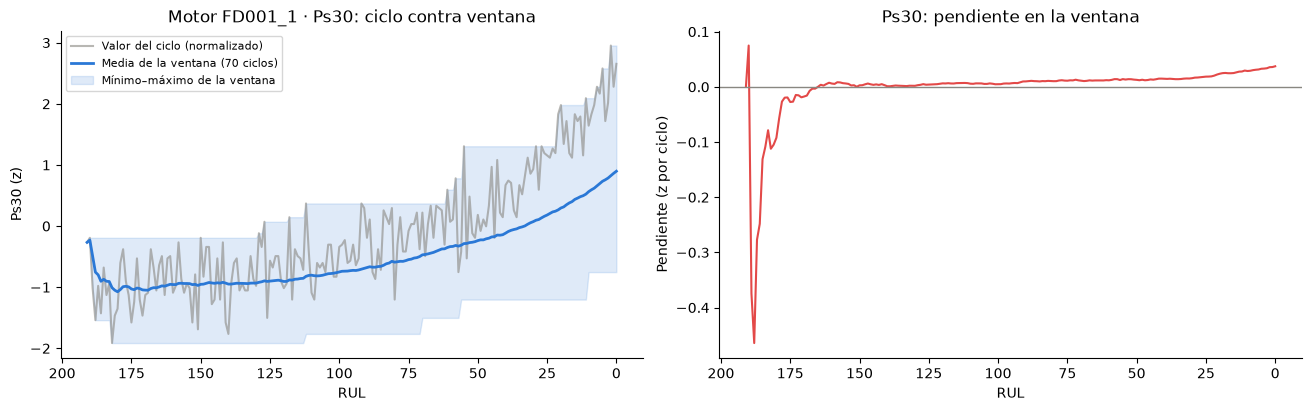

In [31]:
d = datos["FD001"]
motor = d["grupos"] == "FD001_1"
X_m, y_m = d["X_train"][motor], d["y_train_real"][motor]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4), layout="constrained")
ax1.plot(y_m, X_m["Ps30_ult"], color=GRIS, alpha=0.6, label="Valor del ciclo (normalizado)")
ax1.plot(y_m, X_m["Ps30_media"], color=AZUL, lw=2, label=f"Media de la ventana ({VENTANA} ciclos)")
ax1.fill_between(y_m, X_m["Ps30_min"], X_m["Ps30_max"], color=AZUL, alpha=0.15, label="Mínimo–máximo de la ventana")
ax1.set(xlabel="RUL", ylabel="Ps30 (z)", title="Motor FD001_1 · Ps30: ciclo contra ventana")
ax1.invert_xaxis()
ax1.legend(fontsize=8)
ax2.plot(y_m, X_m["Ps30_pend"], color=ROJO)
ax2.axhline(0, color=GRIS, lw=1)
ax2.set(xlabel="RUL", ylabel="Pendiente (z por ciclo)", title="Ps30: pendiente en la ventana")
ax2.invert_xaxis()
plt.show()


- **Izquierda:** el valor de cada ciclo (gris) es muy ruidoso; la media de la ventana (azul) sigue la tendencia de degradación con mucho menos ruido.
- **Derecha:** la pendiente es ≈ 0 mientras el motor está sano y se vuelve positiva al acercarse la falla, así que indica que la degradación se está **acelerando**.
- En los primeros ciclos la pendiente es inestable, porque se calcula con muy pocos puntos.


In [32]:
def correlacion_por_tipo(d):
    corr = d["X_train"].corrwith(d["y_train"]).abs()
    return {tipo: corr[[f"{s}_{tipo}" for s in d["sensores"]]].mean()
            for tipo in ["ult", "media", "desv", "min", "max", "pend"]}

pd.DataFrame({fd: correlacion_por_tipo(d) for fd, d in datos.items()}).round(3)


,FD001,FD002,FD003,FD004
ult,0.621,0.544,0.473,0.433
media,0.573,0.610,0.438,0.414
desv,0.551,0.378,0.453,0.401
min,0.424,0.381,0.313,0.267
max,0.548,0.532,0.525,0.504
pend,0.113,0.083,0.138,0.093


Promedio de |r| con el RUL recortado, por tipo de característica (ventana de 70 ciclos):

| Tipo | FD001 | FD002 | FD003 | FD004 |
|:--|:--:|:--:|:--:|:--:|
| `_ult` (un ciclo) | 0.621 | 0.544 | 0.473 | 0.433 |
| `_media` | 0.573 | 0.610 | 0.438 | 0.414 |
| **`_desv`** | **0.551** | 0.378 | **0.453** | 0.401 |
| `_max` | 0.548 | 0.532 | 0.525 | 0.504 |
| `_min` | 0.424 | 0.381 | 0.313 | 0.267 |
| `_pend` | 0.113 | 0.083 | 0.138 | 0.093 |

- **Con 70 ciclos, la media de la ventana correlaciona menos que el valor del ciclo actual** (salvo en FD002). Una ventana larga incluye ciclos de cuando el motor estaba más sano, así que su media se "atrasa" respecto al estado actual. Con 30 ciclos pasaba lo contrario (por ejemplo, 0.665 contra 0.623 en FD001).
- **La desviación de la ventana gana mucha señal** (0.551 en FD001): cuando el motor se degrada, sus sensores cambian dentro de la ventana, y la ventana larga lo capta mejor.
- **Esta tabla mide cada característica por separado y de forma lineal; no mide lo que aportan juntas.** El modelo combina el valor actual, la media, la desviación, los extremos y la pendiente, y aprovecha relaciones no lineales. Por eso la longitud de la ventana se eligió con validación (10.10), donde 70 ciclos baja el error frente a 30 (24.99 contra 27.64), aunque aquí la media sola correlacione menos.

### 10.7 Evaluación y validación

Funciones que se usarán con todos los modelos:

- **RMSE** contra el RUL real completo (protocolo oficial) y contra el RUL real recortado a 125, para comparar con ambos tipos de referencia (sección 9.4).
- **NASA score** [[1]](#ref1): castiga más predecir de más (tarde) que de menos (temprano).
- **Pliegues por motor** (`GroupKFold`) para la validación cruzada.


In [33]:
def puntaje_nasa(y_real, y_pred):
    """Score NASA: castiga más predecir de más (tarde) que de menos (temprano)."""
    d = np.asarray(y_pred) - np.asarray(y_real)
    return float(np.sum(np.where(d < 0, np.exp(-d / 13) - 1, np.exp(d / 10) - 1)))

def evaluar_test(y_real, y_pred):
    y_pred = np.clip(y_pred, 0, None)
    return {
        "RMSE": rmse(y_real, y_pred),
        f"RMSE (RUL real ≤ {TOPE_REFERENCIA})": rmse(np.minimum(y_real, TOPE_REFERENCIA), y_pred),
        "Score NASA": puntaje_nasa(y_real, y_pred),
    }

def pliegues(fd):
    d = datos[fd]
    return list(GroupKFold(n_splits=N_FOLDS).split(d["X_train"], d["y_train"], d["grupos"]))

# Prueba de las funciones con una predicción trivial: siempre la media del RUL recortado
prueba = {fd: evaluar_test(d["y_test"], np.full(len(d["y_test"]), d["y_train"].mean()))
          for fd, d in datos.items()}
pd.DataFrame(prueba).round(1)

,FD001,FD002,FD003,FD004
RMSE,43.6,54.3,46.1,55.2
RMSE (RUL real ≤ 125),42.5,45.5,44.8,46.4
Score NASA,40439.3,171923.7,73539.4,229742.7


- **NASA score:** con $d = \hat{y} - y$, cada motor suma $e^{-d/13} - 1$ si se predijo de menos y $e^{d/10} - 1$ si se predijo de más. El castigo crece más rápido al predecir de más, que es el error peligroso: decir que al motor le queda más vida de la que tiene.
- `evaluar_test` recorta las predicciones negativas a 0, porque un RUL negativo no tiene sentido.
- `pliegues` separa los motores en 5 grupos: todos los ciclos de un motor quedan en el mismo pliegue.

**Prueba con una predicción trivial** (siempre la media del RUL recortado de train):

| | FD001 | FD002 | FD003 | FD004 |
|:--|:--:|:--:|:--:|:--:|
| RMSE | 43.6 | 54.3 | 46.1 | 55.2 |
| RMSE (RUL real ≤ 125) | 42.5 | 45.5 | 44.8 | 46.4 |
| Score NASA | 40 439 | 171 924 | 73 539 | 229 743 |

Este es el **piso**: cualquier modelo que aprenda algo debe quedar muy por debajo. El baseline a superar es el de la sección 9.4 (por ejemplo, 17.86 / 29.16 / 20.59 / 29.89 en el nivel 1).


### 10.8 Protocolo de validación tipo test

Todas las decisiones (ventana, modelo, hiperparámetros, recorte) se toman con **validación cruzada por motor**; test se usa una sola vez, al final. Para que la validación se parezca a cómo se evalúa test:

- **Pliegues por motor** (`GroupKFold`, barajando los motores): todos los ciclos de un motor quedan en el mismo pliegue. La sección 10.9 muestra por qué.
- **Cortes simulados:** en test, cada motor se observa hasta un corte y se predice una vez. En validación se simula lo mismo: en cada motor se eligen 10 ciclos de corte con la **misma distribución de longitudes observadas en test**. Es información de entrada, no etiquetas. Solo se usan cortes con RUL real ≤ 200, un rango plausible fijado de antemano.
- **Métrica principal:** RMSE contra el RUL **real** en esos cortes, igual que en test. También se reporta el error cerca de la falla (RUL < 50) y el score NASA promedio por corte.
- **Entrenamiento con 1 de cada 5 ciclos:** los ciclos consecutivos de un motor son casi idénticos, así que esto acelera mucho sin perder información.
- **3 repeticiones** con distinta asignación de motores a pliegues. La variación entre repeticiones es el **ruido** de la validación, y sirve para decidir empates.

In [34]:
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import GroupShuffleSplit, KFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import time

CADA = 5             # se entrena con 1 de cada 5 ciclos (los ciclos vecinos son casi idénticos)
CORTES_POR_MOTOR = 10  # puntos de corte simulados por motor de validación
RUL_MAX_EVAL = 200     # solo se simulan cortes con RUL real ≤ 200 (rango plausible, fijado de antemano)
SEMILLAS = (0, 1, 2) # repeticiones de la validación con distinta asignación de motores a pliegues

# Longitudes observadas de los motores de test: información de entrada (no etiquetas)
largos_test = test.groupby(["subset", "engine_id"])["cycle"].max()

def caracteristicas_multiventana(df, sensores, ventanas):
    """Características de una o varias ventanas. 'cycle' y '_ult' no dependen de la ventana: se toman una vez."""
    partes = []
    for k, w in enumerate(ventanas):
        X = caracteristicas_ventana(df, sensores, w)
        if k > 0:
            X = X.drop(columns=["cycle"] + [f"{s}_ult" for s in sensores])
        partes.append(X.add_suffix(f"_w{w}") if len(ventanas) > 1 else X)
    return pd.concat(partes, axis=1)

def construir_X(df, sensores, ventanas):
    """ventanas=None: sin ventana (valores del ciclo actual y número de ciclo)."""
    if ventanas is None:
        return df[["cycle"] + sensores].copy()
    return caracteristicas_multiventana(df, sensores, ventanas)

def preparar(fd, ventanas, normalizar_condicion=True):
    tr = train[train["subset"] == fd]
    te = test[test["subset"] == fd]
    sensores = sensores_del_subset(tr)
    if normalizar_condicion:
        estadisticas = ajustar_normalizador(tr, sensores)
        tr_p, te_p = normalizar(tr, estadisticas, sensores), normalizar(te, estadisticas, sensores)
    else:
        tr_p, te_p = tr, te
    X_train = construir_X(tr_p, sensores, ventanas)
    X_test = construir_X(te_p, sensores, ventanas).loc[te.groupby("engine_id")["cycle"].idxmax()]
    return {
        "X_train": X_train,
        "rul": tr.loc[X_train.index, "RUL"].to_numpy(),
        "ciclo": tr.loc[X_train.index, "cycle"].to_numpy(),
        "grupos": tr.loc[X_train.index, "engine_id"].to_numpy(),
        "X_test": X_test,
        "y_test": te.loc[X_test.index, "RUL_final"].to_numpy(),
        "subset": fd,
    }

def puntos_tipo_test(prep, semilla=0):
    """Simula el corte de test: en cada motor se eligen ciclos de corte con la misma
    distribución de longitudes observadas en test (solo cortes antes de la falla)."""
    rng = np.random.default_rng(semilla)
    largos = largos_test[prep["subset"]].to_numpy()
    ciclo, grupos = prep["ciclo"], prep["grupos"]
    vida = pd.Series(ciclo).groupby(grupos).transform("max").to_numpy()
    marcados = set()
    for motor, v in pd.Series(vida, index=grupos).groupby(level=0).first().items():
        posibles = largos[(largos < v) & (largos >= v - RUL_MAX_EVAL)]   # cortes con 1 ≤ RUL ≤ 200
        if len(posibles) == 0:
            continue
        for corte in rng.choice(posibles, size=CORTES_POR_MOTOR, replace=True):
            marcados.add((motor, int(corte)))
    return np.array([(g, int(c)) in marcados for g, c in zip(grupos, ciclo)])

def metricas(rul, pred):
    cerca = rul < 50
    return {
        "RMSE": rmse(rul, pred),
        f"RMSE (RUL ≤ {TOPE_REFERENCIA})": rmse(np.minimum(rul, TOPE_REFERENCIA), pred),
        "RMSE (RUL < 50)": rmse(rul[cerca], pred[cerca]),
        "Score NASA medio": puntaje_nasa(rul, pred) / len(rul),
    }

def validar(prep, crear_modelo, tope=RUL_TOPE, semilla=0):
    """Validación cruzada por motor, evaluada en puntos de corte parecidos a test."""
    X, rul, ciclo, grupos = prep["X_train"], prep["rul"], prep["ciclo"], prep["grupos"]
    y = rul if tope is None else np.minimum(rul, tope)
    entrenar_en = ciclo % CADA == 0
    evaluar_en = puntos_tipo_test(prep, semilla)
    pred = np.full(len(y), np.nan)
    divisor = GroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=semilla)
    for i_ent, i_val in divisor.split(X, y, grupos):
        i_ent, i_val = i_ent[entrenar_en[i_ent]], i_val[evaluar_en[i_val]]
        modelo = crear_modelo()
        modelo.fit(X.iloc[i_ent], y[i_ent])
        pred[i_val] = np.clip(modelo.predict(X.iloc[i_val]), 0, None)
    return metricas(rul[evaluar_en], pred[evaluar_en])

def validar_repetido(prep, crear_modelo, tope=RUL_TOPE, semillas=SEMILLAS):
    resultados = pd.DataFrame([validar(prep, crear_modelo, tope, s) for s in semillas])
    return resultados.mean(), resultados.std()

def gb_referencia():
    return HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, random_state=SEMILLA)

- `preparar(fd, ventanas, normalizar_condicion)` generaliza la preparación de 10.4. Permite construir datos sin ventana (`None`), con una o varias ventanas, y con o sin normalización, para comparar alternativas con el mismo código.
- `puntos_tipo_test` elige, para cada motor, ciclos de corte tomados de las longitudes reales de los motores de test del mismo subconjunto. El RUL en esos cortes queda distribuido de forma parecida a `RUL_final` (medianas de 84–95 contra 78–88 en test).
- `validar` entrena con 4 pliegues y predice los cortes del quinto, hasta cubrir todos los motores. `validar_repetido` repite con 3 semillas y devuelve la media y la desviación.
- **Limitación:** los cortes simulados todavía tienen algo más de RUL alto que test (23–34 % de puntos con RUL > 125 contra 11–27 %).

### 10.9 ¿Por qué validar por motor (GroupKFold)?

Se aparta un 20 % de los motores como **pseudo-test** (nunca participa en la validación) y con el resto se estima el error de dos formas:

- **KFold por filas:** reparte ciclos al azar, así que el mismo motor queda en entrenamiento y en validación.
- **GroupKFold por motor:** cada motor completo cae en un solo pliegue.

La estimación correcta es la que se acerca al error real en el pseudo-test. Se usa una ventana fija de 30 ciclos, porque aquí se comparan formas de validar, no ventanas.

In [35]:
def experimento_particion(fd, semilla):
    prep = preparar(fd, (30,))   # ventana fija: aquí se comparan formas de validar, no ventanas
    X, rul, ciclo, grupos = prep["X_train"], prep["rul"], prep["ciclo"], prep["grupos"]
    y = np.minimum(rul, RUL_TOPE)
    entrenar_en = ciclo % CADA == 0
    evaluar_en = puntos_tipo_test(prep, semilla)

    # 20 % de los motores se aparta como "pseudo-test": nunca participa en la validación
    i_resto, i_pseudo = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=semilla)
                             .split(X, y, grupos))

    def estimar(divisor, por_motor):
        reales, predichos = [], []
        for a, b in divisor.split(i_resto, groups=grupos[i_resto] if por_motor else None):
            ent, val = i_resto[a], i_resto[b]
            ent, val = ent[entrenar_en[ent]], val[evaluar_en[val]]
            modelo = gb_referencia().fit(X.iloc[ent], y[ent])
            reales.append(rul[val])
            predichos.append(np.clip(modelo.predict(X.iloc[val]), 0, None))
        return rmse(np.concatenate(reales), np.concatenate(predichos))

    ent = i_resto[entrenar_en[i_resto]]
    pseudo = i_pseudo[evaluar_en[i_pseudo]]
    modelo = gb_referencia().fit(X.iloc[ent], y[ent])
    return {
        "KFold por filas": estimar(KFold(n_splits=N_FOLDS, shuffle=True, random_state=semilla), False),
        "GroupKFold por motor": estimar(GroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=semilla), True),
        "Error real (pseudo-test)": rmse(rul[pseudo], np.clip(modelo.predict(X.iloc[pseudo]), 0, None)),
    }

filas = []
for fd in ["FD001", "FD004"]:
    for semilla in SEMILLAS:
        filas.append({"Subconjunto": fd, "Semilla": semilla, **experimento_particion(fd, semilla)})
particion = pd.DataFrame(filas)
display(particion.round(2))
display(particion.groupby("Subconjunto")[["KFold por filas", "GroupKFold por motor", "Error real (pseudo-test)"]]
        .mean().round(2))

,Subconjunto,Semilla,KFold por filas,GroupKFold por motor,Error real (pseudo-test)
0,FD001,0,19.71,25.88,24.12
1,FD001,1,19.03,24.90,25.76
2,FD001,2,17.99,25.34,25.51
3,FD004,0,25.63,30.85,31.15
4,FD004,1,26.33,31.53,31.29
5,FD004,2,25.20,30.68,29.78


,KFold por filas,GroupKFold por motor,Error real (pseudo-test)
Subconjunto,,,
FD001,18.91,25.37,25.13
FD004,25.72,31.02,30.74


| | KFold por filas | GroupKFold por motor | Error real (pseudo-test) |
|:--|:--:|:--:|:--:|
| FD001 | 18.91 | 25.37 | **25.13** |
| FD004 | 25.72 | 31.02 | **30.74** |

- **KFold por filas promete un error 5–6 ciclos menor que el real.** El modelo ve ciclos casi idénticos del mismo motor en entrenamiento y en validación, y "reconoce" al motor en lugar de predecir su degradación.
- **GroupKFold acierta con menos de 0.3 ciclos de diferencia**, porque reproduce la situación de test: predecir motores que el modelo nunca vio.
- Por eso todas las decisiones del proyecto se toman con GroupKFold. Es lo mismo que recomiendan [[5]](#ref5), [[7]](#ref7) y [[8]](#ref8) (sección 9.3); aquí queda comprobado con los datos del proyecto.

### 10.10 Elección de la ventana

Se comparan 8 configuraciones, de la más simple a la más compleja: sin ventana (solo el ciclo actual), ventanas de 10 a 100 ciclos y combinaciones de una corta con una larga. Se usa un modelo de referencia (gradient boosting con parámetros fijos) y el protocolo de 10.8.

**Regla de decisión (fijada antes de ver los resultados):** se elige la configuración **más simple** cuyo error promedio no supere al de la mejor más su ruido ("regla de 1 error estándar"). Entre opciones equivalentes, la más simple tiene menos riesgo de ajustarse a los pliegues por casualidad.

In [36]:
configuraciones = {   # ordenadas de la más simple a la más compleja
    "Sin ventana (1 ciclo)": None,
    "10": (10,),
    "30": (30,),
    "50": (50,),
    "70": (70,),
    "100": (100,),
    "30 + 70": (30, 70),
    "10 + 30 + 70": (10, 30, 70),
}

ciclos_test = test.groupby(["subset", "engine_id"])["cycle"].max()
filas = []
for nombre, ventanas in configuraciones.items():
    inicio = time.time()
    for fd in subsets:
        prep = preparar(fd, ventanas)
        media, desv = validar_repetido(prep, gb_referencia)
        filas.append({"Configuración": nombre, "Subconjunto": fd, "RMSE": media["RMSE"],
                      "ruido": desv["RMSE"], "RUL < 50": media["RMSE (RUL < 50)"]})
    print(f"{nombre:>22}: {time.time() - inicio:.0f} s")

res_ventanas = pd.DataFrame(filas)
tabla_ventanas = res_ventanas.pivot(index="Configuración", columns="Subconjunto", values="RMSE").loc[list(configuraciones)]
tabla_ventanas["Promedio"] = tabla_ventanas[subsets].mean(axis=1)
tabla_ventanas["± ruido"] = res_ventanas.groupby("Configuración")["ruido"].mean()
tabla_ventanas["RUL < 50 (prom.)"] = res_ventanas.groupby("Configuración")["RUL < 50"].mean()
tabla_ventanas["% test incompletos"] = [0.0 if v is None else 100 * (ciclos_test < max(v)).mean()
                                        for v in configuraciones.values()]
display(tabla_ventanas.round(2))

# Regla de 1 error estándar: la configuración más simple que no sea peor que la mejor más su ruido
mejor = tabla_ventanas["Promedio"].idxmin()
umbral = tabla_ventanas.loc[mejor, "Promedio"] + tabla_ventanas.loc[mejor, "± ruido"]
elegida = next(n for n in configuraciones if tabla_ventanas.loc[n, "Promedio"] <= umbral)
VENTANAS = configuraciones[elegida]
print(f"Mejor: {mejor} ({tabla_ventanas.loc[mejor, 'Promedio']:.2f}); umbral = {umbral:.2f}")
print(f"Elegida (más simple dentro del umbral): {elegida} → VENTANAS = {VENTANAS}")

 Sin ventana (1 ciclo): 39 s


                    10: 73 s


                    30: 79 s


                    50: 74 s


                    70: 73 s


                   100: 73 s


               30 + 70: 121 s


          10 + 30 + 70: 278 s


Subconjunto,FD001,FD002,FD003,FD004,Promedio,± ruido,RUL < 50 (prom.),% test incompletos
Configuración,,,,,,,,
Sin ventana (1 ciclo),29.86,30.38,32.25,33.88,31.60,0.63,17.24,0.00
10,29.18,29.43,31.26,33.41,30.82,0.77,15.96,0.00
30,25.12,27.30,27.35,30.78,27.64,0.58,10.03,2.40
50,22.52,25.36,26.15,29.08,25.78,0.62,7.39,7.64
70,21.74,23.91,25.93,28.37,24.99,0.59,6.90,15.56
100,21.29,23.34,25.64,28.10,24.59,0.57,6.81,28.57
30 + 70,21.53,23.70,25.68,28.24,24.79,0.59,6.80,15.56
10 + 30 + 70,21.22,23.60,25.47,28.14,24.61,0.58,6.72,15.56


Mejor: 100 (24.59); umbral = 25.16
Elegida (más simple dentro del umbral): 70 → VENTANAS = (70,)


| Configuración | FD001 | FD002 | FD003 | FD004 | **Promedio** | RUL < 50 | % test incompletos |
|:--|:--:|:--:|:--:|:--:|:--:|:--:|:--:|
| Sin ventana | 29.86 | 30.38 | 32.25 | 33.88 | 31.60 | 17.24 | 0 % |
| 10 | 29.18 | 29.43 | 31.26 | 33.41 | 30.82 | 15.96 | 0 % |
| 30 | 25.12 | 27.30 | 27.35 | 30.78 | 27.64 | 10.03 | 2 % |
| 50 | 22.52 | 25.36 | 26.15 | 29.08 | 25.78 | 7.39 | 8 % |
| **70** | 21.74 | 23.91 | 25.93 | 28.37 | **24.99** | 6.90 | 16 % |
| 100 (mejor) | 21.29 | 23.34 | 25.64 | 28.10 | 24.59 | 6.81 | 29 % |
| 30 + 70 | 21.53 | 23.70 | 25.68 | 28.24 | 24.79 | 6.80 | 16 % |
| 10 + 30 + 70 | 21.22 | 23.60 | 25.47 | 28.14 | 24.61 | 6.72 | 16 % |

Ruido de la validación: ≈ ±0.6 ciclos.

- **Usar ventana es claramente mejor que no usarla:** de 31.60 a ≈ 25, y cerca de la falla de 17.2 a ≈ 6.9.
- **La ventana de 30 ciclos de la literatura deja ≈ 2.6 ciclos de error sobre la mesa** frente a 70.
- La mejor es 100 (24.59). Con su ruido, el umbral es 25.16, y **70 es la más simple dentro del umbral**: queda a 0.4 ciclos de la mejor y deja incompletos al 16 % de los motores de test, contra 29 % con 100.
- Las combinaciones de ventanas no superan a la mejor ventana simple por más que el ruido.

Se elige **una ventana de 70 ciclos**. Por eso en 10.1 se fija `VENTANA = 70`, y la preparación de 10.4–10.6 usa esa ventana.

---

## 11. Modelos de ML tradicional

### 11.1 Escalera de baselines

Para justificar cada decisión con el mismo código y protocolo, se construye una **escalera**: cada paso agrega **una sola** decisión al anterior, y la diferencia de error muestra cuánto aporta.

| Paso | Configuración | Qué justifica |
|:--|:--|:--|
| 0 | Media trivial | Piso |
| 1 | Regresión lineal, 1 ciclo, sin normalizar, sin recorte | Baseline ingenuo |
| 2 | Random Forest, 1 ciclo, sin normalizar, con recorte | Reproduce el baseline de Kaggle (sección 9.4) con este código |
| 3 | + normalización por condición | Normalización |
| 4 | + ventanas de 70 ciclos | Ventanas |
| 4b | Ventanas **sin** normalizar (control) | Interacción ventanas × normalización |
| 5 | + gradient boosting ajustado | Modelo e hiperparámetros |

In [37]:
def lineal():
    return make_pipeline(StandardScaler(), LinearRegression())

def bosque():
    return RandomForestRegressor(n_estimators=100, min_samples_leaf=5, max_features=0.3,
                                 n_jobs=8, random_state=SEMILLA)

escalera = {
    "1. Lineal · 1 ciclo · sin normalizar · sin recorte": dict(ventanas=None, normalizar=False, modelo=lineal, tope=None),
    "2. Random Forest · 1 ciclo · sin normalizar · con recorte": dict(ventanas=None, normalizar=False, modelo=bosque, tope=RUL_TOPE),
    "3. + normalización por condición": dict(ventanas=None, normalizar=True, modelo=bosque, tope=RUL_TOPE),
    "4. + ventanas": dict(ventanas=VENTANAS, normalizar=True, modelo=bosque, tope=RUL_TOPE),
    "4b. ventanas sin normalizar (control)": dict(ventanas=VENTANAS, normalizar=False, modelo=bosque, tope=RUL_TOPE),
}

preparados = {}
def preparado(fd, ventanas, normalizar_condicion):
    clave = (fd, ventanas, normalizar_condicion)
    if clave not in preparados:
        preparados[clave] = preparar(fd, ventanas, normalizar_condicion)
    return preparados[clave]

filas = []
for paso, cfg in escalera.items():
    inicio = time.time()
    for fd in subsets:
        media, desv = validar_repetido(preparado(fd, cfg["ventanas"], cfg["normalizar"]), cfg["modelo"], cfg["tope"])
        filas.append({"Paso": paso, "Subconjunto": fd, "RMSE": media["RMSE"], "ruido": desv["RMSE"]})
    print(f"{paso[:45]:>45}: {time.time() - inicio:.0f} s")
cv_escalera = pd.DataFrame(filas)

1. Lineal · 1 ciclo · sin normalizar · sin re: 3 s


2. Random Forest · 1 ciclo · sin normalizar ·: 17 s


             3. + normalización por condición: 19 s


                                4. + ventanas: 67 s


        4b. ventanas sin normalizar (control): 67 s


### 11.2 Ajuste de hiperparámetros (paso 5)

Para cada subconjunto se prueban 8 combinaciones de gradient boosting (número de árboles, hojas por árbol y mínimo de muestras por hoja) con validación cruzada por motor. Se elige la de menor error y se vuelve a validar con 3 semillas.

In [38]:
rejilla = [dict(max_iter=it, learning_rate=0.05, max_leaf_nodes=hojas, min_samples_leaf=minimo)
           for it in (300, 600) for hojas in (15, 31) for minimo in (20, 50)]

mejores_parametros, filas = {}, []
for fd in subsets:
    prep = preparado(fd, VENTANAS, True)
    resultados = [validar(prep, lambda p=p: HistGradientBoostingRegressor(random_state=SEMILLA, **p))["RMSE"]
                  for p in rejilla]
    mejores_parametros[fd] = rejilla[int(np.argmin(resultados))]
    media, desv = validar_repetido(prep, lambda p=mejores_parametros[fd]: HistGradientBoostingRegressor(random_state=SEMILLA, **p))
    filas.append({"Paso": "5. + gradient boosting ajustado", "Subconjunto": fd, "RMSE": media["RMSE"], "ruido": desv["RMSE"]})
    print(fd, mejores_parametros[fd], f"RMSE = {media['RMSE']:.2f}")

cv_escalera = pd.concat([cv_escalera[cv_escalera["Paso"] != "5. + gradient boosting ajustado"], pd.DataFrame(filas)])
tabla_escalera = cv_escalera.pivot(index="Paso", columns="Subconjunto", values="RMSE")
tabla_escalera["Promedio"] = tabla_escalera[subsets].mean(axis=1)
display(tabla_escalera.round(2))

FD001 {'max_iter': 300, 'learning_rate': 0.05, 'max_leaf_nodes': 31, 'min_samples_leaf': 50} RMSE = 21.48


FD002 {'max_iter': 300, 'learning_rate': 0.05, 'max_leaf_nodes': 15, 'min_samples_leaf': 50} RMSE = 23.86


FD003 {'max_iter': 300, 'learning_rate': 0.05, 'max_leaf_nodes': 15, 'min_samples_leaf': 50} RMSE = 25.54


FD004 {'max_iter': 300, 'learning_rate': 0.05, 'max_leaf_nodes': 15, 'min_samples_leaf': 20} RMSE = 28.38


Subconjunto,FD001,FD002,FD003,FD004,Promedio
Paso,,,,,
1. Lineal · 1 ciclo · sin normalizar · sin recorte,35.16,35.71,49.12,46.70,41.67
2. Random Forest · 1 ciclo · sin normalizar · con recorte,29.65,30.79,32.20,34.83,31.87
3. + normalización por condición,29.65,30.58,32.19,34.29,31.68
4. + ventanas,22.37,24.91,26.53,29.23,25.76
4b. ventanas sin normalizar (control),22.36,32.73,26.54,36.24,29.47
5. + gradient boosting ajustado,21.48,23.86,25.54,28.38,24.81


Hiperparámetros elegidos (tasa de aprendizaje 0.05 en todos):

| | Árboles | Hojas | Mín. por hoja |
|:--|:--:|:--:|:--:|
| FD001 | 300 | 31 | 50 |
| FD002 | 300 | 15 | 50 |
| FD003 | 300 | 15 | 50 |
| FD004 | 300 | 15 | 20 |

Error de validación (RMSE en cortes tipo test):

| Paso | FD001 | FD002 | FD003 | FD004 | **Promedio** |
|:--|:--:|:--:|:--:|:--:|:--:|
| 1. Lineal, 1 ciclo, sin normalizar, sin recorte | 35.16 | 35.71 | 49.12 | 46.70 | 41.67 |
| 2. Random Forest, 1 ciclo, sin normalizar, con recorte | 29.65 | 30.79 | 32.20 | 34.83 | 31.87 |
| 3. + normalización por condición | 29.65 | 30.58 | 32.19 | 34.29 | 31.68 |
| 4. + ventanas | 22.37 | 24.91 | 26.53 | 29.23 | 25.76 |
| 4b. Ventanas sin normalizar (control) | 22.36 | 32.73 | 26.54 | 36.24 | 29.47 |
| **5. + gradient boosting ajustado** | **21.48** | **23.86** | **25.54** | **28.38** | **24.81** |

- **Árboles contra lineal (1 → 2):** −9.8 ciclos. La degradación no es lineal, y el recorte del RUL también ayuda.
- **Normalización (2 → 3):** casi no cambia **sin ventanas**: un árbol puede separar las 6 condiciones por sí mismo usando los valores de los sensores.
- **Ventanas (3 → 4):** −5.9 ciclos. Es la mejora más grande después del cambio de modelo.
- **Normalización con ventanas (4 contra 4b):** en FD002 y FD004 quitar la normalización sube el error en 7–8 ciclos. Una ventana sin normalizar mezcla ciclos de 6 condiciones distintas, y su media y su pendiente pierden sentido. En FD001 y FD003 (una sola condición) no cambia nada. **La normalización importa precisamente porque se usan ventanas.**
- **Gradient boosting ajustado (4 → 5):** −1 ciclo adicional.

### 11.3 Sensibilidad del recorte del RUL

Se compara entrenar sin recorte, con recorte a 125 (el valor habitual en la literatura) y con recorte a 130, con el modelo del paso 5.

In [39]:
filas = []
for fd in subsets:
    prep = preparado(fd, VENTANAS, True)
    modelo = lambda p=mejores_parametros[fd]: HistGradientBoostingRegressor(random_state=SEMILLA, **p)
    for tope in (None, 125, 130):
        media, _ = validar_repetido(prep, modelo, tope)
        filas.append({"Recorte": "Sin recorte" if tope is None else str(tope), "Subconjunto": fd,
                      "RMSE": media["RMSE"], "RMSE (RUL < 50)": media["RMSE (RUL < 50)"],
                      "Score NASA medio": media["Score NASA medio"]})
recorte_cv = pd.DataFrame(filas)
display(recorte_cv.pivot(index="Recorte", columns="Subconjunto", values="RMSE").round(2))
display(recorte_cv.pivot(index="Recorte", columns="Subconjunto", values="Score NASA medio").round(2))

Subconjunto,FD001,FD002,FD003,FD004
Recorte,,,,
125,22.47,24.78,26.96,29.78
130,21.48,23.86,25.54,28.38
Sin recorte,22.87,25.10,34.77,32.78


Subconjunto,FD001,FD002,FD003,FD004
Recorte,,,,
125,14.77,18.88,2.403000e+01,1111.42
130,11.98,16.23,1.947000e+01,1153.39
Sin recorte,73.35,148.27,1.573320e+08,8959.50


| Recorte | FD001 | FD002 | FD003 | FD004 |
|:--|:--:|:--:|:--:|:--:|
| Sin recorte | 22.87 | 25.10 | 34.77 | 32.78 |
| 125 | 22.47 | 24.78 | 26.96 | 29.78 |
| **130** | **21.48** | **23.86** | **25.54** | **28.38** |

Score NASA promedio por corte:

| Recorte | FD001 | FD002 | FD003 | FD004 |
|:--|:--:|:--:|:--:|:--:|
| Sin recorte | 73.4 | 148.3 | 1.6 × 10⁸ | 8 959.5 |
| 125 | 14.8 | 18.9 | 24.0 | 1 111.4 |
| 130 | 12.0 | 16.2 | 19.5 | 1 153.4 |

- **Sin recorte es claramente peor**, sobre todo en FD003 y FD004. Su score NASA se dispara porque el modelo predice vidas largas que los sensores no pueden distinguir, y se equivoca "tarde".
- **130 es mejor que 125 en los cuatro subconjuntos** (≈ 1–1.4 ciclos, por encima del ruido de ±0.6). Por eso se usa **130**.
- **Matiz:** los cortes simulados tienen algo más de RUL alto que test (sección 10.8), lo que favorece un poco a los topes altos. El score NASA de FD004 es la única métrica que favorece a 125, y por poco.
- El RMSE contra el RUL recortado se sigue reportando con tope **125**, para comparar con [[5]](#ref5).

### 11.4 Evaluación final en test

Cada paso de la escalera se entrena con todo el train de su subconjunto y se evalúa **una sola vez** en test: una predicción por motor, en su último ciclo observado, contra `RUL_final`. Ninguna decisión anterior usó estos resultados.

In [40]:
modelos_finales = {
    "0. Media trivial": None,
    **{paso: (cfg["ventanas"], cfg["normalizar"], cfg["modelo"], cfg["tope"]) for paso, cfg in escalera.items()},
    "5. + gradient boosting ajustado": (VENTANAS, True, None, RUL_TOPE),
}

filas = []
for paso, cfg in modelos_finales.items():
    inicio = time.time()
    for fd in subsets:
        if cfg is None:
            prep = preparado(fd, None, True)
            pred = np.full(len(prep["y_test"]), np.minimum(prep["rul"], RUL_TOPE).mean())
        else:
            ventanas, norm, crear, tope = cfg
            prep = preparado(fd, ventanas, norm)
            if crear is None:
                crear = lambda p=mejores_parametros[fd]: HistGradientBoostingRegressor(random_state=SEMILLA, **p)
            y = prep["rul"] if tope is None else np.minimum(prep["rul"], tope)
            modelo = crear().fit(prep["X_train"], y)
            pred = modelo.predict(prep["X_test"])
        filas.append({"Paso": paso, "Subconjunto": fd, **evaluar_test(prep["y_test"], pred)})
    print(f"{paso[:45]:>45}: {time.time() - inicio:.0f} s")

resultados_test = pd.DataFrame(filas)
for metrica in ["RMSE", f"RMSE (RUL real ≤ {TOPE_REFERENCIA})", "Score NASA"]:
    print(metrica)
    display(resultados_test.pivot(index="Paso", columns="Subconjunto", values=metrica).round(2))

                             0. Media trivial: 0 s
1. Lineal · 1 ciclo · sin normalizar · sin re: 0 s


2. Random Forest · 1 ciclo · sin normalizar ·: 6 s


             3. + normalización por condición: 6 s


                                4. + ventanas: 33 s


        4b. ventanas sin normalizar (control): 31 s


              5. + gradient boosting ajustado: 5 s
RMSE


Subconjunto,FD001,FD002,FD003,FD004
Paso,,,,
0. Media trivial,43.60,54.32,46.08,55.23
1. Lineal · 1 ciclo · sin normalizar · sin recorte,30.85,31.55,55.85,46.77
2. Random Forest · 1 ciclo · sin normalizar · con recorte,18.35,27.35,19.24,28.26
3. + normalización por condición,18.36,27.60,19.22,28.45
4. + ventanas,13.49,22.35,12.95,24.36
4b. ventanas sin normalizar (control),13.46,29.52,12.82,29.14
5. + gradient boosting ajustado,13.56,21.82,11.19,23.89


RMSE (RUL real ≤ 125)


Subconjunto,FD001,FD002,FD003,FD004
Paso,,,,
0. Media trivial,42.54,45.53,44.82,46.42
1. Lineal · 1 ciclo · sin normalizar · sin recorte,31.11,29.69,57.24,50.40
2. Random Forest · 1 ciclo · sin normalizar · con recorte,17.35,16.19,18.13,18.16
3. + normalización por condición,17.36,16.69,18.11,18.64
4. + ventanas,12.53,10.66,11.88,13.30
4b. ventanas sin normalizar (control),12.53,18.81,11.73,18.34
5. + gradient boosting ajustado,12.72,10.75,10.27,13.08


Score NASA


Subconjunto,FD001,FD002,FD003,FD004
Paso,,,,
0. Media trivial,40439.31,171923.73,7.353938e+04,229742.68
1. Lineal · 1 ciclo · sin normalizar · sin recorte,6734.15,16820.93,7.865377e+08,318030.48
2. Random Forest · 1 ciclo · sin normalizar · con recorte,597.92,9895.82,1.172660e+03,5835.10
3. + normalización por condición,597.68,9628.45,1.170560e+03,5896.95
4. + ventanas,311.16,3493.29,3.245500e+02,3355.79
4b. ventanas sin normalizar (control),313.30,12058.32,3.143800e+02,8239.33
5. + gradient boosting ajustado,343.94,2981.29,2.412800e+02,3425.94


**RMSE en test** (contra el RUL real):

| Paso | FD001 | FD002 | FD003 | FD004 |
|:--|:--:|:--:|:--:|:--:|
| 0. Media trivial | 43.60 | 54.32 | 46.08 | 55.23 |
| 1. Lineal, 1 ciclo, sin normalizar, sin recorte | 30.85 | 31.55 | 55.85 | 46.77 |
| 2. Random Forest, 1 ciclo, sin normalizar, con recorte | 18.35 | 27.35 | 19.24 | 28.26 |
| 3. + normalización por condición | 18.36 | 27.60 | 19.22 | 28.45 |
| 4. + ventanas | 13.49 | 22.35 | 12.95 | 24.36 |
| 4b. Ventanas sin normalizar (control) | 13.46 | 29.52 | 12.82 | 29.14 |
| **5. + gradient boosting ajustado** | **13.56** | **21.82** | **11.19** | **23.89** |

**Comparación con los baselines** (RMSE en test):

| | FD001 | FD002 | FD003 | FD004 |
|:--|:--:|:--:|:--:|:--:|
| Baseline externo nivel 1 (Kaggle, sin ventanas) [[2]](#ref2), [[3]](#ref3) | 17.86 | 29.16 | 20.59 | 29.89 |
| Baseline interno (paso 2, mismo protocolo) | 18.35 | 27.35 | 19.24 | 28.26 |
| Baseline externo nivel 2 (todas las fuentes) | 16.06 | 26.93 | 16.28 | 27.63 |
| **Modelo final (paso 5)** | **13.56** | **21.82** | **11.19** | **23.89** |
| Mejora frente al nivel 2 | −2.5 | −5.1 | −5.1 | −3.7 |

**Contra el RUL real recortado a 125** (para comparar con [[5]](#ref5)):

| | FD001 | FD002 | FD003 | FD004 |
|:--|:--:|:--:|:--:|:--:|
| *Fleet-readiness*, LightGBM [[5]](#ref5) | 11.46 | 11.03 | 9.96 | 11.59 |
| **Modelo final** | 12.72 | **10.75** | 10.27 | 13.08 |

**Score NASA del modelo final:** 344 / 2 981 / 241 / 3 426.

- **El modelo final supera a los dos baselines externos en los cuatro subconjuntos**, por 2.5 a 5.1 ciclos frente al nivel 2.
- **El baseline interno (paso 2) reproduce al de Kaggle con ≈ 1–2 ciclos de diferencia.** Eso valida la comparación: la mejora viene de las decisiones del proyecto, no de una forma distinta de medir.
- **Frente a [[5]](#ref5), que es un trabajo cuidadoso con ventanas y normalización, el modelo queda cerca:** mejor en FD002, a 0.3 en FD003 y a 1.3–1.5 en FD001 y FD004.
- **Test confirma lo que mostró la validación:**
  - las ventanas son la mejora más grande (≈ 5 ciclos);
  - la normalización solo importa con ventanas (FD002: 22.35 contra 29.52; FD004: 24.36 contra 29.14);
  - el ajuste de gradient boosting aporta poco en FD001 y más en FD003.
- FD002 y FD004 siguen siendo los más difíciles: muchos de sus motores de test tienen RUL real mayor que el tope, y un modelo recortado no puede predecir esos valores.

---

## 12. Registro de decisiones

| Decisión | Alternativas consideradas | Evidencia | Sección |
|:--|:--|:--|:--|
| **Validar separando por motor** (GroupKFold) | KFold por filas | KFold por filas subestima el error en 5–6 ciclos; GroupKFold acierta con < 0.3 de diferencia frente a motores apartados | 9.3, 10.9 |
| **Cortes de validación tipo test** | Evaluar todos los ciclos | Evaluar todos los ciclos favorece ventanas largas y "sin recorte"; los cortes simulados reproducen la distribución de RUL de test | 10.8 |
| **5 pliegues, 3 repeticiones** | 10 pliegues, una sola repetición | Con 100 motores, 5 pliegues dejan 20 motores por validación; las repeticiones miden el ruido (≈ ±0.6) que se usa para decidir empates | 10.8 |
| **Recortar el RUL a 130** | Sin recorte, 125 | Sin recorte es peor y su score NASA se dispara; 130 supera a 125 en los 4 subconjuntos por ≈ 1–1.4 ciclos | 4.3, 6.2, 6.4, 9.3, 11.3 |
| **Normalizar por condición** | Sin normalizar | Sin ventanas casi no importa; con ventanas, quitarla sube el error 7–8 ciclos en FD002/FD004 | 6.3, 7.3, 9.3, 11.1 |
| **Sensores:** descartar los constantes dentro de alguna condición | Usar los 21 | Son constantes (σ = 0) y en FD002 causaban división entre cero | 6.1, 6.4, 10.2, 10.5 |
| **Ventana de 70 ciclos** | Sin ventana, 10–100, combinaciones | Sin ventana: 31.60; con 70: 24.99. Es la más simple dentro del ruido de la mejor (100), con la mitad de motores de test incompletos | 10.10 |
| **Un modelo por subconjunto** | Un modelo para todos | Los dos modos de falla mueven sensores en direcciones opuestas (FD003/FD004) | 6.4, 7.3, 9.3 |
| **Gradient boosting ajustado** | Lineal, Random Forest | Lineal: 41.67; Random Forest con ventanas: 25.76; gradient boosting ajustado: 24.81 | 11.1, 11.2 |
| **Métricas:** RMSE contra RUL real, RMSE contra RUL ≤ 125 y score NASA | Solo RMSE | RMSE real para el protocolo oficial; recortado para comparar con [[5]](#ref5); score NASA para el costo de predecir tarde | 9.1, 10.7 |
| **Test se usa una sola vez** | Elegir con test | Todas las decisiones se toman con validación; test solo se reporta al final | 10.8, 11.4 |

---

## 13. El método explicado en palabras sencillas

Este proyecto busca predecir **cuántos ciclos de vida le quedan a un motor** (RUL) a partir de sus sensores. Cada paso del método responde a un problema concreto de los datos.

1. **Qué se predice.** En train cada motor opera hasta fallar, así que en cada ciclo se sabe cuánto le faltaba (`RUL = último ciclo − ciclo actual`). En test la serie se corta antes de la falla, y `RUL_FD00X` dice cuánto le quedaba en ese último ciclo.
2. **Separar el efecto de la condición de vuelo.** En FD002 y FD004 los motores vuelan en 6 condiciones, y un sensor cambia mucho más por la condición que por el desgaste. Cada lectura se compara con lo normal *para su condición*, como medir la fiebre comparando con la temperatura normal de esa persona. En FD002 la correlación con el RUL pasa de 0.017 a 0.447 (7.3).
3. **Quitar sensores que no informan.** Un sensor que no cambia no puede decir nada del desgaste (6.1, 10.2).
4. **Recortar el RUL.** Al principio el motor está sano y sus sensores no cambian (6.2, 6.4): uno al que le quedan 300 ciclos se ve igual que uno al que le quedan 150. Mientras el RUL es mayor que 130, se le pide al modelo lo mismo: "le queda mucho". Sin recorte el error y el score NASA empeoran (11.3).
5. **Un modelo por subconjunto.** En FD003 y FD004 hay dos tipos de falla que mueven algunos sensores en direcciones opuestas (6.4, 7.3).
6. **Ventanas deslizantes.** Una lectura es muy ruidosa. Se resumen los últimos 70 ciclos de cada sensor: la media quita el ruido y la pendiente dice si el deterioro se acelera. Sin ventana el error de validación es 31.60; con 70 ciclos, 24.99 (10.10).
7. **Validar con motores que el modelo nunca vio.** Dos ciclos seguidos de un motor son casi idénticos. Si un motor queda repartido entre entrenamiento y evaluación, el modelo lo reconoce en lugar de predecir, como un examen con preguntas ya vistas. Repartiendo por filas, la validación prometía 18.91 cuando el error real era 25.13; repartiendo por motor estimó 25.37 (10.9).
8. **Que la práctica se parezca al examen.** En test cada motor se evalúa una vez, donde fue cortado. La validación simula esos cortes (10.8). Una primera versión que evaluaba todos los ciclos llevaba a conclusiones equivocadas, como preferir no recortar.
9. **Medir el ruido y elegir lo más simple.** La validación se repite 3 veces; su variación (≈ ±0.6) es ruido. Entre opciones que difieren menos que eso, se elige la más simple (10.10).
10. **Cambiar una cosa a la vez.** La escalera (11.1) mide cuánto aporta cada decisión. Así se descubrió que la normalización importa sobre todo junto con las ventanas.
11. **Por qué árboles.** El RUL es plano mientras el motor está sano y cae rápido al final; una recta no puede representar esa forma. La regresión lineal quedó casi 17 ciclos peor (11.2).
12. **El examen final se presenta una sola vez.** Todas las decisiones se tomaron con validación; test se usa una sola vez (11.4).
13. **Tres métricas.** RMSE (error promedio en ciclos, la métrica oficial), RMSE contra el RUL recortado a 125 (para comparar con [[5]](#ref5)) y score NASA (castiga más predecir de más, que es el error peligroso [[1]](#ref1)).
14. **Baselines justos.** Además de los resultados de otros trabajos (9.4), el paso 2 de la escalera los imita con el mismo código y protocolo. Queda cerca de ellos, y el modelo final los supera en los cuatro subconjuntos.

**Limitaciones:**
- Los cortes simulados en validación todavía tienen algo más de motores con RUL alto que test, lo que favorece un poco a los recortes altos.
- La normalización se ajusta con todo el train de cada subconjunto, no dentro de cada pliegue. El efecto medido en otro trabajo es despreciable [[5]](#ref5).
- Al inicio del proyecto se probaron el recorte y la ventana con métodos más sencillos, mirando test en una ocasión. Las decisiones finales salen del protocolo de validación (10.8–10.10, 11.3), no de esos números.

---

## Referencias

<a id="ref1"></a>[1] Saxena, A., Goebel, K., Simon, D., & Eklund, N. (2008). Damage Propagation Modeling for Aircraft Engine Run-to-Failure Simulation. *Proceedings of the 1st International Conference on Prognostics and Health Management (PHM08)*, Denver, CO.

<a id="ref2"></a>[2] Kirstein, C. (2022). *Predictive Maintenance NASA turbofan Regression* [Notebook de Kaggle]. https://www.kaggle.com/code/carlkirstein/predictive-maintenance-nasa-turbofan-regression

<a id="ref3"></a>[3] Sahoo, B. *rul_codes_open: Remaining useful life prediction codes* [Repositorio de GitHub]. https://github.com/biswajitsahoo1111/rul_codes_open

<a id="ref4"></a>[4] Momt, Y. (2023). *RUL prediction using LSTM for Aircraft Engine* [Notebook de Kaggle]. https://www.kaggle.com/code/yahyamomtaz/rul-prediction-using-lstm-for-aircraft-engine

<a id="ref5"></a>[5] Elsamahy, A. E. (2026). *Fleet Readiness: Engine RUL on NASA C-MAPSS* [Notebook de Kaggle]. https://www.kaggle.com/code/amiresamelsamahy/fleet-readiness-engine-rul-on-nasa-c-mapss

<a id="ref6"></a>[6] PiyushBhamare2111. *predictive-maintenance-rul* [Repositorio de GitHub]. https://github.com/PiyushBhamare2111/predictive-maintenance-rul

<a id="ref7"></a>[7] yz-shift. *engine-rul-prediction* [Repositorio de GitHub]. https://github.com/yz-shift/engine-rul-prediction

<a id="ref8"></a>[8] vatsav4. *rul-prediction-cmapss* [Repositorio de GitHub]. https://github.com/vatsav4/rul-prediction-cmapss

<a id="ref9"></a>[9] Dyaus2. *turbowatch* [Repositorio de GitHub]. https://github.com/Dyaus2/turbowatch

<a id="ref10"></a>[10] KayDee6070. *turbofan-rul* [Repositorio de GitHub]. https://github.com/KayDee6070/turbofan-rul

<a id="ref11"></a>[11] dossebamba. *cmapss-prediction-rul* [Repositorio de GitHub]. https://github.com/dossebamba/cmapss-prediction-rul

<a id="ref12"></a>[12] Parisi, F. (2025). *NASA Turbofan Jet Engine* [Notebook de Kaggle]. https://www.kaggle.com/code/fernandoparisi/nasa-turbofan-jet-engine

<a id="ref13"></a>[13] Zilli, P. K. (2019). *Predicting Failures* [Notebook de Kaggle]. https://www.kaggle.com/code/pkzilli/predicting-failures

<a id="ref14"></a>[14] Cabrera Romo, J. P. (2023). *Predicting remaining useful life Turbofan Engine* [Notebook de Kaggle]. https://www.kaggle.com/code/jospablocabreraromo/predicting-remaining-useful-life-turbofan-engine

<a id="ref15"></a>[15] Guajardo, D. (2025). *Predicting Turbofan Engine RUL* [Notebook de Kaggle]. https://www.kaggle.com/code/danielrayguajardo/predicting-turbofan-engine-rul

<a id="ref16"></a>[16] Babu, G. S., Zhao, P., & Li, X.-L. (2016). Deep Convolutional Neural Network Based Regression Approach for Estimation of Remaining Useful Life. *Database Systems for Advanced Applications (DASFAA 2016)*, Lecture Notes in Computer Science, vol. 9642. Springer.

<a id="ref17"></a>[17] Heimes, F. O. (2008). Recurrent neural networks for remaining useful life estimation. *Proceedings of the 1st International Conference on Prognostics and Health Management (PHM08)*, Denver, CO.
